# 02_profile - подготовка данных, паспорт, пропуски и распределения

Единый источник данных: датасет с Kaggle (`kagglehub`, `andrejmaximov/moex-stock`, файл `prices_ix_secs.csv`)

| Этап | Что добавляется | Таблица | Разделы |
|---|---|---|---|
| **1. Базовая таблица** | котировки + IMOEX + сектор и тип акции (из `config/universe.csv`) | `base` | 1–6 |
| **2. Доходности и признаки** | 12 признаков и 3 флага | `ds` | 7–11 |
| **3. Таргет** | `target_vol_21d` и `split` | `ds` (итоговая форма `model_dataset`) | 12 |
| Ограничения, вопросы к команде, идеи для следующего этапа | | | 13–15 |

В датасете Kaggle есть котировки, закрытие IMOEX и сектор, заполненный для всех лет. Готовых признаков и таргета в нем нет: доходности, волатильности, флаги (этап 2) и таргет с `split` (этап 3) считаются здесь. Столбцы переименованы под наш план (`ticker` → `secid`, `close_ix` → `imoex_close`), служебный `Unnamed: 0` убран, сектор сверен с `config/universe.csv`, тип акции `is_pref` взят оттуда.

Таблицы предварительные: после выхода общей таблицы ноутбук перезапускаем на ней.

In [1]:
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()


def hist_panel(frame, cols, ncols=4, clip=(0.01, 0.99), logx=False, bins=60, color="#4c72b0"):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.2 * nrows))
    for ax, c in zip(np.ravel(axes), cols):
        s = frame[c].dropna()
        if logx:
            s = np.log10(s[s > 0])
        lo, hi = s.quantile(clip[0]), s.quantile(clip[1])
        inside = s[(s >= lo) & (s <= hi)]
        ax.hist(inside, bins=bins, color=color)
        ax.set_title(f"{c}{' (log10)' if logx else ''}\nn={len(s):,}, вне графика: {len(s) - len(inside):,}", fontsize=9)
        ax.set_ylabel("число строк")
    for ax in np.ravel(axes)[len(cols):]:
        ax.axis("off")
    fig.tight_layout()
    plt.show()

/opt/anaconda3/lib/python3.13/site-packages/requests/__init__.py:113: RequestsDependencyWarning: urllib3 (2.3.0) or chardet (7.4.3)/charset_normalizer (3.3.2) doesn't match a supported version!
  warnings.warn(


---
# ЭТАП 1. Базовая таблица
Котировки, сектор и тип акции, значение IMOEX. Признаки доходностей и волатильности здесь еще не считаются.
## 1. Загрузка и подготовка данных Kaggle
### 1.1 Загрузка и контроль

In [2]:
path = kagglehub.dataset_download("andrejmaximov/moex-stock/versions/2")   # версия закреплена для воспроизводимости
kg = pd.read_csv(Path(path) / "prices_ix_secs.csv", parse_dates=["trade_date"])
universe = pd.read_csv(ROOT / "config" / "universe.csv", parse_dates=["snapshot_date"])
print("Kaggle:", kg.shape, "| universe:", universe.shape)
print("столбцы Kaggle:", kg.columns.tolist())

Kaggle: (76843, 13) | universe: (44, 6)
столбцы Kaggle: ['Unnamed: 0', 'trade_date', 'close_ix', 'boardid', 'ticker', 'open', 'high', 'low', 'close', 'volume', 'value', 'numtrades', 'sector']


Что есть в файле и что мы с ним делаем:

| В файле Kaggle | У нас | Комментарий |
|---|---|---|
| `Unnamed: 0` | убираем | служебный номер строки |
| `ticker` | `secid` | тикер акции (ключ) |
| `close_ix` | `imoex_close` | закрытие IMOEX |
| `open`, `high`, `low`, `close`, `volume`, `value`, `numtrades`, `boardid`, `trade_date` | без изменений | котировки |
| `sector` | сверяем с `universe.csv` | сектор акции |
| `is_pref` | берем из `universe.csv` | в файле Kaggle его нет |

In [3]:
q = kg.drop(columns=["Unnamed: 0"]).rename(columns={"ticker": "secid", "close_ix": "imoex_close", "sector": "sector_kaggle"})

print("ключ trade_date + secid уникален:", not q.duplicated(["trade_date", "secid"]).any())
print("режимы торгов:", q.boardid.unique().tolist(), "| в universe:", universe.boardid.unique().tolist())
print("тикеры Kaggle == тикеры universe:", set(q.secid) == set(universe.secid))
print("значений IMOEX на одну дату (максимум):", q.groupby("trade_date")["imoex_close"].nunique().max())
print("пустых значений sector в Kaggle:", q["sector_kaggle"].isna().sum())
print("признаков (волатильность, доходности, таргет) в файле Kaggle нет:", not any(c.startswith(("ret_", "vol_", "target")) for c in kg.columns))

ключ trade_date + secid уникален: True
режимы торгов: ['TQBR'] | в universe: ['TQBR']
тикеры Kaggle == тикеры universe: True
значений IMOEX на одну дату (максимум): 1
пустых значений sector в Kaggle: 0
признаков (волатильность, доходности, таргет) в файле Kaggle нет: True


**Календарь торгов.** Ищем разрывы в датах: в 2022 году биржа не торговала акциями, и в этом датасете (в отличие от сырых данных API) строк за эти дни нет.

In [4]:
cal_dates = pd.Series(np.sort(q["trade_date"].unique()))
gaps = pd.DataFrame({"с": cal_dates.shift(1), "по": cal_dates, "дней": cal_dates.diff().dt.days})
gaps = gaps[gaps["дней"] > 10]
gaps[["с", "по"]] = gaps[["с", "по"]].apply(lambda c: c.dt.date)
print("торговых дат:", len(cal_dates), "| разрывов в календаре больше 10 дней:", len(gaps))
gaps

торговых дат: 2222 | разрывов в календаре больше 10 дней: 1


,с,по,дней
1050,2022-02-25,2022-03-24,27.0000


### 1.2 Базовая таблица `base`: котировки + сектор и тип акции + IMOEX

In [5]:
n0 = len(q)
base = q.merge(universe[["secid", "sector", "is_pref"]], on="secid", how="left", validate="many_to_one")
assert len(base) == n0, "объединение изменило число строк"
print("сектор Kaggle совпадает с сектором universe:", f"расхождений {(base.sector_kaggle != base.sector).sum()} из {len(base):,}")
base = base.drop(columns=["sector_kaggle"])
base = base.sort_values(["secid", "trade_date"]).reset_index(drop=True)

print(f"base: {base.shape[0]:,} строк, {base.shape[1]} столбцов:", base.columns.tolist())
print("несовпавших ключей: sector =", base.sector.isna().sum(), "| is_pref =", base.is_pref.isna().sum(), "| imoex_close =", base.imoex_close.isna().sum())
print("ключ trade_date + secid уникален:", not base.duplicated(["trade_date", "secid"]).any())

сектор Kaggle совпадает с сектором universe: расхождений 0 из 76,843
base: 76,843 строк, 13 столбцов: ['trade_date', 'imoex_close', 'boardid', 'secid', 'open', 'high', 'low', 'close', 'volume', 'value', 'numtrades', 'sector', 'is_pref']
несовпавших ключей: sector = 0 | is_pref = 0 | imoex_close = 0
ключ trade_date + secid уникален: True


- Датасет Kaggle содержит 76 843 строки и 44 бумаги. Готовых признаков в нем нет: в файле только котировки, IMOEX и сектор. После переименования столбцов, удаления служебного `Unnamed: 0` и объединения с `universe.csv` получилась таблица `base` (13 столбцов).

- Ключ `trade_date + secid` уникален, режим торгов один (`TQBR`), тикеры Kaggle совпадают с `universe.csv`, на каждую дату одно значение IMOEX, пропусков сектора нет. Сектор в Kaggle совпал с сектором из `universe.csv` во всех строках (расхождений 0). Объединение `many_to_one` не меняет число строк. В календаре один разрыв больше 10 дней (2022-02-25 → 2022-03-24, остановка торгов): строк за эти даты в датасете нет.

--> Данные Kaggle совпали с API MOEX по цене, объему, числу сделок и IMOEX на всех 76 843 строках (проверено отдельно), так что для нашей задачи их можно использовать. Признаки (этап 2) и таргет (этап 3) считаем сами ниже.

## 2. Паспорт выборки
**Одна строка** — одна акция за один торговый день. Ключ: `trade_date + secid`.

In [6]:
passport = pd.Series({
    "строк": len(base),
    "бумаг": base.secid.nunique(),
    "первая дата": base.trade_date.min().date(),
    "последняя дата": base.trade_date.max().date(),
    "торговых дат": base.trade_date.nunique(),
    "секторов": base.sector.nunique(),
    "привилегированных бумаг": int(base.drop_duplicates("secid").is_pref.sum()),
    "дата снимка состава IMOEX (universe)": universe.snapshot_date.max().date(),
})
passport.to_frame("значение")

,значение
строк,76843
бумаг,44
первая дата,2018-01-03
последняя дата,2026-11-02
торговых дат,2222
секторов,9
привилегированных бумаг,4
дата снимка состава IMOEX (universe),2026-11-02


In [7]:
base.dtypes.to_frame('тип')

,тип
trade_date,datetime64[ns]
imoex_close,float64
boardid,object
secid,object
open,float64
high,float64
low,float64
close,float64
volume,int64
value,float64


In [8]:
base.head()

,trade_date,imoex_close,boardid,secid,open,high,low,close,volume,value,numtrades,sector,is_pref
0,2018-01-03,"2,152.9700",TQBR,AFKS,12.4850,12.5500,12.2600,12.3500,20687500,"256,119,052.0000",5071,финансы,0
1,2018-01-04,"2,197.6000",TQBR,AFKS,12.3650,12.4650,12.2400,12.3850,14880200,"183,676,750.0000",4362,финансы,0
2,2018-01-05,"2,207.4100",TQBR,AFKS,12.3850,12.4200,12.2200,12.3900,11072000,"136,535,338.0000",3666,финансы,0
3,2018-01-09,"2,225.3900",TQBR,AFKS,12.5450,12.8400,12.5050,12.7150,30905600,"393,081,866.5000",9167,финансы,0
4,2018-01-10,"2,232.2700",TQBR,AFKS,12.7850,12.8350,12.5200,12.7000,11774300,"148,739,015.5000",4446,финансы,0


In [9]:
base.describe(include='all').T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
trade_date,76843,NaN,NaN,NaN,2022-11-02 03:13:32.498210816,2018-01-03 00:00:00,2020-09-15 00:00:00,2023-01-19 00:00:00,2025-02-07 00:00:00,2026-11-02 00:00:00,NaN
imoex_close,"76,843.0000",NaN,NaN,NaN,"2,814.1123","1,916.9700","2,434.6000","2,759.1200","3,114.4100","4,287.5200",484.1501
boardid,76843,1,TQBR,76843,NaN,NaN,NaN,NaN,NaN,NaN,NaN
secid,76843,44,AFKS,2222,NaN,NaN,NaN,NaN,NaN,NaN,NaN
open,"76,605.0000",NaN,NaN,NaN,"4,206.6395",0.0140,49.5200,208.0000,941.2000,"184,450.0000","20,691.4175"
high,"76,605.0000",NaN,NaN,NaN,"4,252.3403",0.0151,50.1800,210.7100,954.8000,"186,100.0000","20,894.3252"
low,"76,605.0000",NaN,NaN,NaN,"4,153.0529",0.0139,48.6900,205.0000,924.7000,"182,800.0000","20,452.6543"
close,"76,605.0000",NaN,NaN,NaN,"4,205.3482",0.0144,49.5000,207.9700,940.6000,"185,000.0000","20,687.6344"
volume,"76,843.0000",NaN,NaN,NaN,"1,316,307,806.1516",0.0000,"594,348.0000","3,515,270.0000","19,731,140.0000","703,268,100,000.0000","13,717,630,896.5380"
value,"76,843.0000",NaN,NaN,NaN,"1,912,447,883.0676",0.0000,"293,518,471.3750","761,298,321.5000","1,828,775,401.7000","238,583,656,296.9000","4,023,917,838.3782"


- Период 2018-01-03 — 2026-11-02, 2 222 торговые даты, 44 бумаги, 9 секторов, 4 привилегированные бумаги (SBERP, SNGSP, TATNP, TRNFP). Цены лежат в диапазоне от 0.014 до 185 000 руб., оборот в среднем 1.9 млрд, а медиана 0.76 млрд.

- Таблица `describe(include="all")`: у `open/high/low/close` по 238 пустых значений, у `volume`, `value`, `numtrades` пропусков нет, `boardid` принимает одно значение.

## 3. Пропуски в исходных данных

In [10]:
miss = base.isna().sum().to_frame("пропусков")
miss["доля, %"] = miss["пропусков"] / len(base) * 100
print(f"общая доля пустых ячеек: {base.isna().sum().sum() / base.size * 100:.2f}%")
print(f"доля строк хотя бы с одним пропуском: {base.isna().any(axis=1).mean() * 100:.2f}%")
miss[miss["пропусков"] > 0].sort_values("пропусков", ascending=False)

общая доля пустых ячеек: 0.10%
доля строк хотя бы с одним пропуском: 0.31%


,пропусков,"доля, %"
open,238,0.3097
high,238,0.3097
low,238,0.3097
close,238,0.3097


### 3.1 Исходные данные: пустые `open/high/low/close`

In [11]:
src = base[base["open"].isna()]
print("строк с пустыми OHLC:", len(src), f"({len(src) / len(base) * 100:.2f}%)")
print("из них volume == 0:", (src.volume == 0).sum(), "| numtrades == 0:", (src.numtrades == 0).sum(), "| value == 0:", (src.value == 0).sum())
print("пустой open, но есть high/low/close:", (base.open.isna() & base[["high", "low", "close"]].notna().any(axis=1)).sum())
print("есть сделки (volume > 0), но нет цены:", ((base.volume > 0) & base.close.isna()).sum())
src.groupby("secid").size().sort_values(ascending=False).head(10).to_frame("дней без сделок")

строк с пустыми OHLC: 238 (0.31%)
из них volume == 0: 238 | numtrades == 0: 238 | value == 0: 238
пустой open, но есть high/low/close: 0
есть сделки (volume > 0), но нет цены: 0


,дней без сделок
secid,
OZON,39
CNRU,39
HEAD,29
VKCO,27
MDMG,21
YDEX,12
RUAL,5
VTBR,5
GMKN,5


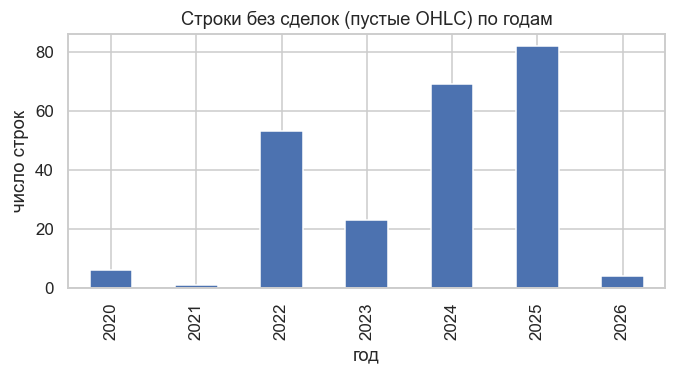

In [12]:
by_year = src.groupby(src.trade_date.dt.year).size().rename("дней без сделок")
fig, ax = plt.subplots(figsize=(7, 3))
by_year.plot.bar(ax=ax, color="#4c72b0")
ax.set(title="Строки без сделок (пустые OHLC) по годам", xlabel="год", ylabel="число строк")
plt.show()

### 3.2 Объединение: сектор, тип акции и IMOEX

In [13]:
print("пропусков sector:", base.sector.isna().sum(), "| is_pref:", base.is_pref.isna().sum(), "| imoex_close:", base.imoex_close.isna().sum())
print("разрывов календаря больше 10 дней:", len(gaps), "(остановка торгов 2022: строк за эти даты в датасете нет)")

пропусков sector: 0 | is_pref: 0 | imoex_close: 0
разрывов календаря больше 10 дней: 1 (остановка торгов 2022: строк за эти даты в датасете нет)


В базовой таблице пустых ячеек 0.10%, строк хотя бы с одним пропуском 0.31%. Пропуски только в `open/high/low/close` (по 238 строк). Сектор, тип акции и значение IMOEX заполнены везде.

**Причина:**  Во всех 238 строках `volume`, `numtrades` и `value` равны нулю, то есть сделок в эти дни не было. Строк со сделками, но без цены, нет. Чаще всего это новые бумаги: OZON, CNRU (по 39 дней), HEAD (29), VKCO (27).

--> Пропуски исходных полей объясняются отсутствием торгов, а не ошибкой данных, и заполнять их не нужно. Для расчета признаков решение (флэт-цена или исключение) за Пашей, у нас сейчас флэт-цена.

## 4. Распределения исходных полей (детальнее)


In [14]:
RAW_NUM = ["open", "high", "low", "close", "volume", "value", "numtrades", "imoex_close"]
base[RAW_NUM].describe(percentiles=[.01, .25, .5, .75, .99]).T

,count,mean,std,min,1%,25%,50%,75%,99%,max
open,"76,605.0000","4,206.6395","20,691.4175",0.0140,0.0360,49.5200,208.0000,941.2000,"147,348.0000","184,450.0000"
high,"76,605.0000","4,252.3403","20,894.3252",0.0151,0.0363,50.1800,210.7100,954.8000,"149,000.0000","186,100.0000"
low,"76,605.0000","4,153.0529","20,452.6543",0.0139,0.0357,48.6900,205.0000,924.7000,"145,598.0000","182,800.0000"
close,"76,605.0000","4,205.3482","20,687.6344",0.0144,0.0360,49.5000,207.9700,940.6000,"147,148.0000","185,000.0000"
volume,"76,843.0000","1,316,307,806.1516","13,717,630,896.5380",0.0000,"1,126.4200","594,348.0000","3,515,270.0000","19,731,140.0000","39,215,687,600.0000","703,268,100,000.0000"
value,"76,843.0000","1,912,447,883.0676","4,023,917,838.3782",0.0000,"5,641,594.4700","293,518,471.3750","761,298,321.5000","1,828,775,401.7000","18,124,094,785.8520","238,583,656,296.9000"
numtrades,"76,843.0000","28,759.0566","38,697.5364",0.0000,364.0000,"8,384.0000","17,832.0000","34,892.5000","175,985.2800","1,559,658.0000"
imoex_close,"76,843.0000","2,814.1123",484.1501,"1,916.9700","2,043.7100","2,434.6000","2,759.1200","3,114.4100","4,174.7600","4,287.5200"


### 4.1 Цены, объем и оборот (логарифмический масштаб)

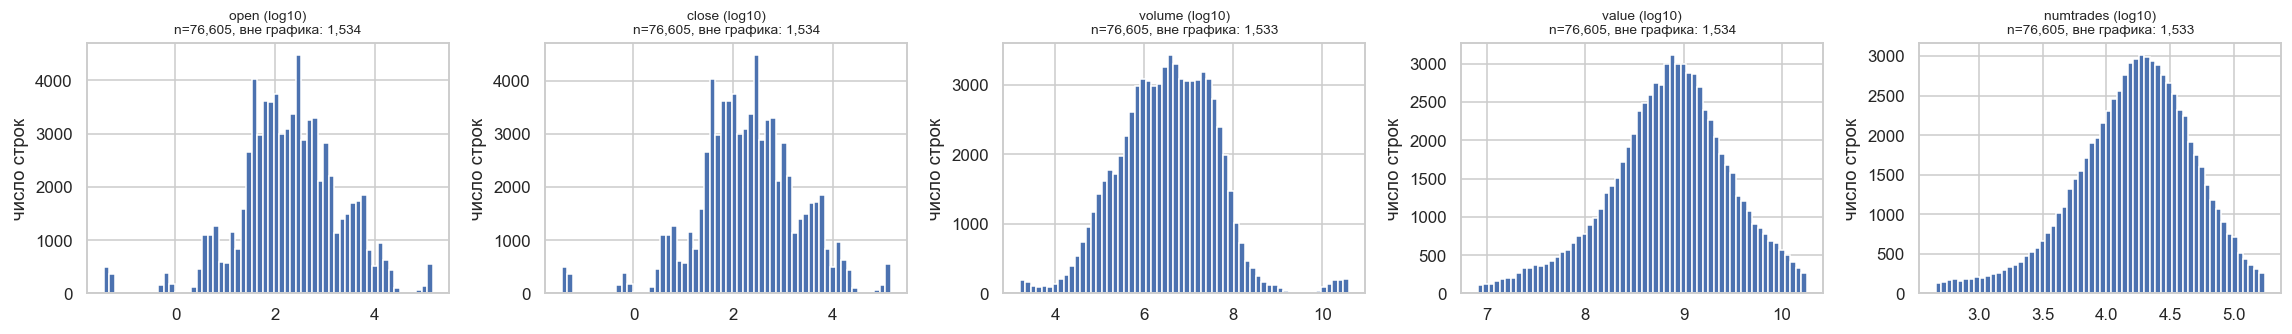

In [15]:
hist_panel(base, ['open', 'close', 'volume', 'value', 'numtrades'], ncols=5, logx=True)

### 4.2 Значение IMOEX (один ряд по датам)

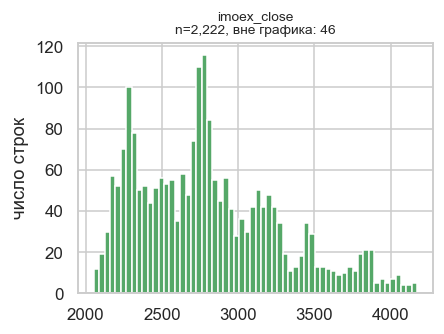

In [16]:
hist_panel(base.drop_duplicates('trade_date'), ['imoex_close'], ncols=1, color='#55a868')


- **Цены** `open/high/low/close` лежат в диапазоне от 0.014 до 185 000 руб., 99-й перцентиль около 147 000. Эти уровни определяются номиналом акции и сплитами, а не размером бумаги.
- **Объем** (`volume`, число бумаг): медиана 3.5 млн, 99-й перцентиль 39 млрд, максимум 703 млрд. Такие значения у VTBR до консолидации 2024 года, когда акция стоила сотые доли рубля.
- **Оборот** (`value`, руб.): медиана 0.76 млрд, среднее 1.9 млрд, 99-й перцентиль 18 млрд, максимум 239 млрд. Распределение сильно скошено вправо.
- **Число сделок:** медиана 17.8 тыс., максимум 1.56 млн в день.
- **IMOEX:** от 1 917 до 4 288, медиана 2 759.


-->
- Уровни цен разных бумаг и лет сравнивать нельзя, нужны доходности (этап 2).
- Объем в штуках не скорректирован на сплиты, а оборот в рублях сопоставим между датами, поэтому для ликвидности надежнее `value`.
- Оборот и число сделок нужно логарифмировать, иначе несколько самых ликвидных бумаг определяют масштаб.

## 5. Категории и состав выборки

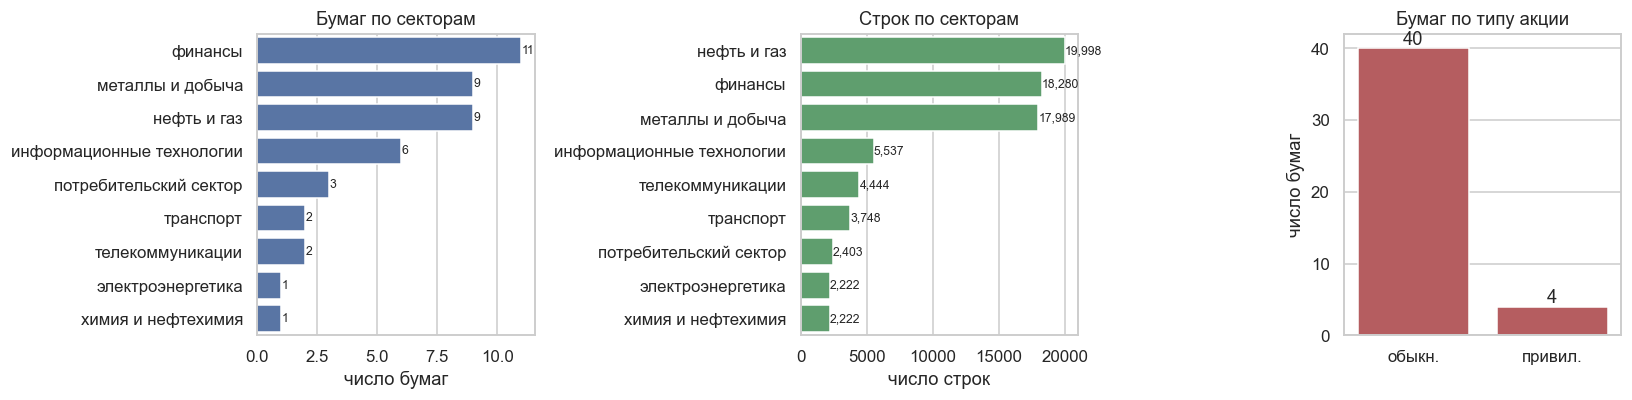

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
s = base.drop_duplicates("secid")["sector"].value_counts()
sns.barplot(x=s.values, y=s.index, ax=axes[0], color="#4c72b0"); axes[0].set(title="Бумаг по секторам", xlabel="число бумаг", ylabel="")
r = base["sector"].value_counts()
sns.barplot(x=r.values, y=r.index, ax=axes[1], color="#55a868"); axes[1].set(title="Строк по секторам", xlabel="число строк", ylabel="")
p = base.drop_duplicates("secid")["is_pref"].map({0: "обыкн.", 1: "привил."}).value_counts()
sns.barplot(x=p.index, y=p.values, ax=axes[2], color="#c44e52"); axes[2].set(title="Бумаг по типу акции", ylabel="число бумаг", xlabel="")
for ax in axes[:2]:
    for pt in ax.patches:
        ax.annotate(f"{int(pt.get_width()):,}", (pt.get_width(), pt.get_y() + pt.get_height() / 2), va="center", fontsize=8)
for pt in axes[2].patches:
    axes[2].annotate(int(pt.get_height()), (pt.get_x() + pt.get_width() / 2, pt.get_height()), ha="center", va="bottom")
fig.tight_layout(); plt.show()

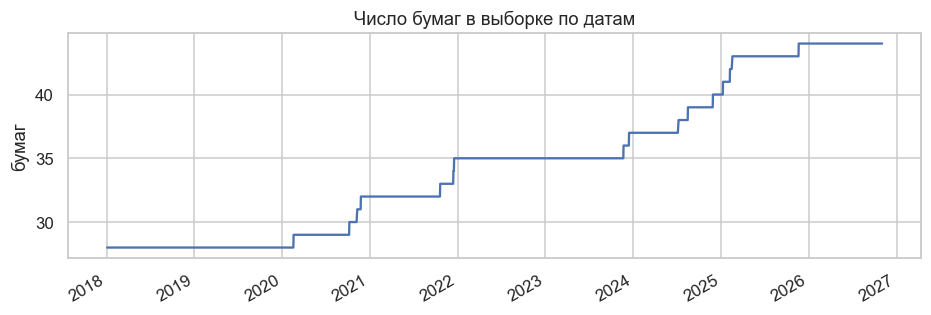

In [18]:
n_t = base.groupby("trade_date")["secid"].nunique()
fig, ax = plt.subplots(figsize=(10, 3))
n_t.plot(ax=ax, color="#4c72b0")
ax.set(title="Число бумаг в выборке по датам", xlabel="", ylabel="бумаг")
plt.show()

Бумаг по секторам: финансы 11, металлы и добыча 9, нефть и газ 9, IT 6, потребительский сектор 3, транспорт 2, телекоммуникации 2, электроэнергетика 1, химия и нефтехимия 1. Обыкновенных акций 40, привилегированных 4. Число бумаг в выборке по датам растет от 28 в 2018 году до 44 к концу 2025 года.


--> 
- Классы несбалансированы: два сектора представлены одной бумагой, привилегированные составляют 4 из 44. Выводы по ним ненадежны, а при разбиении по времени такие бумаги легко потерять в одной из частей.
- Состав выборки меняется во времени: 28 бумаг с 2018 года, остальные входят позже. Усреднение по датам смешивает разные наборы бумаг.

### 5.1 Исторический состав IMOEX: с какого момента наши бумаги в индексе
 Мы берем 44 бумаги, которые входят в IMOEX на 2026-11-02 (`config/universe.csv`), и не меняем список, даже если раньше состав индекса был другим. Задача проекта: прогнозировать волатильность именно этих бумаг, поэтому бумаги, которые выбыли из индекса, в выборку не добавляем.

Исторический состав (`data/raw/imoex_composition.csv`, скрипт `scripts/download_moex_events.py`, первый торговый день каждого месяца из MOEX ISS) нужен здесь для двух проверок:
- **с какого момента** каждая из наших бумаг входит в индекс и есть ли по ней строки в Kaggle за это время;
- **какой была выборка в прошлом**: в ранние годы часть наших бумаг еще не входила в индекс, это важно для интерпретации результатов.

Часть бумаг сменила тикер после редомициляции, в составе индекса они записаны старым тикером, поэтому приводим их к нашему (`YNDX → YDEX`, `TCSG → T`, `FIVE → X5`, `HHRU → HEAD`, `AGRO → RAGR`, `MAIL → VKCO`).

In [19]:
comp = pd.read_csv(ROOT / "data" / "raw" / "imoex_composition.csv", parse_dates=["tradedate"])
RENAMES = {"YNDX": "YDEX", "TCSG": "T", "FIVE": "X5", "HHRU": "HEAD", "AGRO": "RAGR", "MAIL": "VKCO"}
comp["secid"] = comp["ticker"].replace(RENAMES)
OUR = set(base["secid"])
n_dates = comp["tradedate"].nunique()
print(f"Дат состава: {n_dates} (первый торговый день месяца, {comp.tradedate.min().date()} — {comp.tradedate.max().date()}; марта 2022 нет из-за остановки торгов)")
print(f"Наши бумаги в составе на последнюю дату: {comp.loc[comp.tradedate == comp.tradedate.max(), 'secid'].isin(OUR).sum()} из {len(OUR)}")

ours_comp = comp[comp["secid"].isin(OUR)].copy()
in_base = set(zip(base["secid"], base["trade_date"]))
ours_comp["есть_строка"] = [(s, t) in in_base for s, t in zip(ours_comp["secid"], ours_comp["tradedate"])]

hist = ours_comp.groupby("secid").agg(
    тикер_в_индексе=("ticker", lambda t: ", ".join(sorted(set(t)))),
    в_индексе_с=("tradedate", "min"), месяцев_в_индексе=("tradedate", "size"),
    месяцев_в_индексе_без_строк=("есть_строка", lambda v: int((~v).sum())), средний_вес_pct=("weight", "mean"))
hist["первая_строка_в_Kaggle"] = base.groupby("secid")["trade_date"].min()
hist["группа"] = np.select(
    [hist["месяцев_в_индексе_без_строк"] > 0, hist["месяцев_в_индексе"] == n_dates],
    ["в индексе раньше, чем есть строки", "в индексе весь период"], "вошла в индекс позже")
hist["группа"].value_counts().to_frame("бумаг")

Дат состава: 106 (первый торговый день месяца, 2018-01-03 — 2026-11-02; марта 2022 нет из-за остановки торгов)
Наши бумаги в составе на последнюю дату: 44 из 44


,бумаг
группа,
в индексе весь период,27
вошла в индекс позже,11
"в индексе раньше, чем есть строки",6


In [20]:
# бумаги, у которых история в индексе длиннее, чем история в данных, и бумаги, вошедшие позже
hist[hist["группа"] != "в индексе весь период"].sort_values(["группа", "в_индексе_с"]).round(2)

,тикер_в_индексе,в_индексе_с,месяцев_в_индексе,месяцев_в_индексе_без_строк,средний_вес_pct,первая_строка_в_Kaggle,группа
secid,,,,,,,
RAGR,"AGRO, RAGR",2018-01-03,32,27,0.5500,2025-02-17,"в индексе раньше, чем есть строки"
YDEX,"YDEX, YNDX",2018-01-03,100,74,4.7000,2024-07-08,"в индексе раньше, чем есть строки"
X5,"FIVE, X5",2018-04-02,93,79,1.7300,2025-01-09,"в индексе раньше, чем есть строки"
T,"T, TCSG",2020-01-03,82,58,2.9500,2024-11-28,"в индексе раньше, чем есть строки"
VKCO,"MAIL, VKCO",2020-10-01,73,15,0.6000,2021-12-14,"в индексе раньше, чем есть строки"
HEAD,"HEAD, HHRU",2021-01-04,43,20,0.7200,2024-08-16,"в индексе раньше, чем есть строки"
OZON,OZON,2021-01-04,58,0,1.2600,2020-11-24,вошла в индекс позже
ENPG,ENPG,2022-01-03,58,0,0.4000,2020-02-18,вошла в индекс позже
POSI,POSI,2023-10-02,38,0,0.3800,2021-12-17,вошла в индекс позже


In [21]:
# по годам: сколько наших бумаг в индексе, сколько из них с данными, и доля наших строк до входа бумаги в индекс
per = ours_comp.groupby("tradedate").agg(наших_бумаг_в_индексе=("secid", "size"), из_них_со_строками=("есть_строка", "sum"),
                                         их_вес_в_индексе_pct=("weight", "sum"))
per["наших_бумаг_со_строками"] = base[base["trade_date"].isin(per.index)].groupby("trade_date")["secid"].nunique()

in_comp = set(zip(ours_comp["secid"], ours_comp["tradedate"]))
rows = base[base["trade_date"].isin(per.index)]
rows = rows.assign(до_входа_в_индекс=[(s, t) not in in_comp for s, t in zip(rows["secid"], rows["trade_date"])])
per_y = per.groupby(per.index.year).mean().round(1)
per_y["наших_строк_вне_индекса_pct"] = rows.groupby(rows["trade_date"].dt.year)["до_входа_в_индекс"].mean().mul(100).round(1)
per_y

,наших_бумаг_в_индексе,из_них_со_строками,их_вес_в_индексе_pct,наших_бумаг_со_строками,наших_строк_вне_индекса_pct
tradedate,,,,,
2018,29.2000,27.0000,91.9000,28.0000,3.6000
2019,29.0000,27.0000,93.2000,28.0000,3.6000
2020,30.2000,27.0000,92.5000,29.2000,7.4000
2021,33.0000,28.0000,92.2000,32.2000,13.0000
2022,33.7000,30.0000,92.9000,35.0000,14.3000
2023,34.0000,30.2000,93.0000,35.1000,13.8000
2024,36.2000,33.1000,93.9000,37.8000,12.6000
2025,38.8000,38.8000,97.3000,42.7000,9.2000
2026,43.5000,43.5000,99.2000,44.0000,1.2000


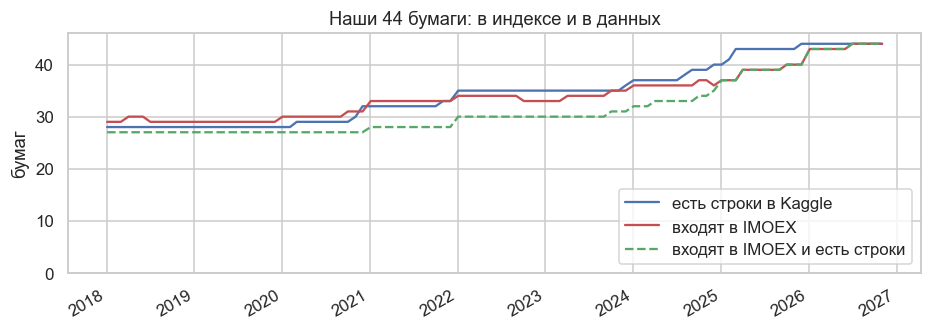

In [22]:
fig, ax = plt.subplots(figsize=(10, 3.2))
per["наших_бумаг_со_строками"].plot(ax=ax, color="#4c72b0", label="есть строки в Kaggle")
per["наших_бумаг_в_индексе"].plot(ax=ax, color="#c44e52", label="входят в IMOEX")
per["из_них_со_строками"].plot(ax=ax, color="#55a868", ls="--", label="входят в IMOEX и есть строки")
ax.set(title="Наши 44 бумаги: в индексе и в данных", xlabel="", ylabel="бумаг", ylim=(0, 46))
ax.legend(loc="lower right"); plt.show()

Из 44 бумаг 27 входят в IMOEX весь период 2018-2026 годов, и данные по ним есть за все это время. Еще 11 вошли в индекс позже (с 2021 по 2026 год), но строки по ним есть и до входа: например, BSPB торгуется в данных с 2018 года, а в индексе с 2024-04. У 6 бумаг история в индексе длиннее, чем в данных: они входили в IMOEX под старым тикером, а в Kaggle есть только с нового. Это YDEX (YNDX, 74 месяца без строк, данные с 2024-07-08), X5 (FIVE, 79 месяцев, с 2025-01-09), T (TCSG, 58 месяцев, с 2024-11-28), RAGR (AGRO, 27), HEAD (HHRU, 20) и VKCO (MAIL, 15).

В 2018 году в индекс входили 29 из наших бумаг, к 2026 году все 44. Строки по нашим бумагам на даты состава есть у 28 в 2018 году и у 44 в 2026. В 2021–2024 годах 12-14% наших строк приходятся на дни, когда бумаги еще не было в индексе.

-->
- Фиксированный состав: модель обучается на истории тех бумаг, которые в индексе сейчас. Результаты относятся именно к ним и не описывают индекс в прошлом целиком. Бумаги, которые выбыли из индекса, в выборку не попадают, поэтому средний риск в ранние годы может быть ниже, чем у индекса в то время (смещение выживших). 
- Строки до входа бумаги в индекс оставляем: бумага та же, ее волатильность в прошлом тоже информативна. Если понадобится, долю таких строк можно учитывать при оценке (в 2021–2024 годах это 12-14%).
- **Бумаги, сменившие тикер, используются в выборке целиком, и их история под старым тикером будет добавлена в датасет.** Это те же компании из нашего списка, поэтому состав выборки не меняется, удлиняется только история:

| Бумага в списке | Старый тикер | Месяцев в индексе без строк | Сейчас данные с |
|---|---|---|---|
| YDEX | YNDX | 74 | 2024-07-08 |
| X5 | FIVE | 79 | 2025-01-09 |
| T | TCSG | 58 | 2024-11-28 |
| RAGR | AGRO | 27 | 2025-02-17 |
| HEAD | HHRU | 20 | 2024-08-16 |
| VKCO | MAIL | 15 | 2021-12-14 |


## 6. Сводные таблицы по исходным полям
### 6.1 По бумагам

In [23]:
raw_by_secid = base.assign(no_trades=base["volume"] == 0).groupby("secid").agg(
    сектор=("sector", "first"),
    привилегированная=("is_pref", "first"),
    строк=("trade_date", "size"),
    первая_дата=("trade_date", "min"),
    последняя_дата=("trade_date", "max"),
    дней_без_сделок=("no_trades", "sum"),
    медиана_value=("value", "median"),
    медиана_numtrades=("numtrades", "median"),
).sort_values("строк", ascending=False)
raw_by_secid["первая_дата"] = raw_by_secid["первая_дата"].dt.date
raw_by_secid["последняя_дата"] = raw_by_secid["последняя_дата"].dt.date
raw_by_secid

,сектор,привилегированная,строк,первая_дата,последняя_дата,дней_без_сделок,медиана_value,медиана_numtrades
secid,,,,,,,,
AFKS,финансы,0,2222,2018-01-03,2026-11-02,1,"630,661,325.1500","15,589.5000"
SBER,финансы,0,2222,2018-01-03,2026-11-02,1,"10,601,569,582.2000","92,027.0000"
NVTK,нефть и газ,0,2222,2018-01-03,2026-11-02,1,"1,537,300,112.7000","24,875.0000"
AFLT,транспорт,0,2222,2018-01-03,2026-11-02,1,"725,897,698.5000","20,423.0000"
PLZL,металлы и добыча,0,2222,2018-01-03,2026-11-02,4,"1,464,502,912.1000","17,699.0000"
ROSN,нефть и газ,0,2222,2018-01-03,2026-11-02,1,"1,928,620,362.1750","37,111.5000"
RTKM,телекоммуникации,0,2222,2018-01-03,2026-11-02,1,"204,856,615.7500","8,136.0000"
RUAL,металлы и добыча,0,2222,2018-01-03,2026-11-02,5,"452,603,617.1500","19,734.5000"
SBERP,финансы,1,2222,2018-01-03,2026-11-02,1,"869,924,003.8500","17,996.0000"


### 6.2 По секторам и типу акции

In [24]:
def raw_group(frame, key):
    return frame.assign(no_trades=frame["volume"] == 0).groupby(key).agg(
        бумаг=("secid", "nunique"),
        строк=("trade_date", "size"),
        доля_дней_без_сделок_pct=("no_trades", lambda s: s.mean() * 100),
        медиана_value=("value", "median"),
        медиана_numtrades=("numtrades", "median"),
    )

print("По секторам:")
display(raw_group(base, "sector").sort_values("строк", ascending=False))
print("По типу акции:")
display(raw_group(base.assign(тип=base["is_pref"].map({0: "обыкновенная", 1: "привилегированная"})), "тип"))

По секторам:


,бумаг,строк,доля_дней_без_сделок_pct,медиана_value,медиана_numtrades
sector,,,,,
нефть и газ,9,19998,0.0650,"1,318,563,693.3500","21,548.5000"
финансы,11,18280,0.1149,"681,603,900.8500","17,474.0000"
металлы и добыча,9,17989,0.1445,"876,860,433.0000","20,089.0000"
информационные технологии,6,5537,2.6910,"665,928,281.0000","19,512.0000"
телекоммуникации,2,4444,0.0450,"400,873,229.2500","11,259.5000"
транспорт,2,3748,0.1067,"503,162,927.0000","16,535.0000"
потребительский сектор,3,2403,0.8739,"121,007,961.9000","9,420.0000"
химия и нефтехимия,1,2222,0.0450,"330,343,540.0000","7,437.0000"
электроэнергетика,1,2222,0.0450,"458,916,374.0000","17,213.0000"


По типу акции:


,бумаг,строк,доля_дней_без_сделок_pct,медиана_value,медиана_numtrades
тип,,,,,
обыкновенная,40,67955,0.3385,"795,693,241.3000","18,632.0000"
привилегированная,4,8888,0.0900,"600,430,490.5500","13,555.5000"



- **По бумагам:** оборот очень различается. Медиана `value` у SBER около 10.6 млрд руб. в день, у менее ликвидных бумаг (RTKM, TATNP, TRNFP) 0.2–0.4 млрд. У TRNFP медиана числа сделок всего 1 586 при сопоставимом обороте: торгуется крупными лотами.
- **По секторам:** самый высокий медианный оборот у нефти и газа (1.32 млрд), самый низкий у потребительского сектора (0.12 млрд). Дни без сделок почти не встречаются (0.04–0.15%), кроме IT (2.7%) и потребительского сектора (0.9%): там много новых бумаг.
- **По типу акции:** у привилегированных медианный оборот ниже (0.60 против 0.80 млрд), а дней без сделок меньше (0.09% против 0.34%).



--> Различия по ликвидности между бумагами достигают двух порядков, поэтому признаки, зависящие от оборота, нужно нормировать. В секторах с 1–3 бумагами цифры отражают особенности отдельных эмитентов, а не сектора.

### Итог этапа 1
**Что доступно:** базовая таблица из 76 843 строк (44 бумаги, 2018-01-03 — 2026-11-02): котировки, сектор и тип акции, IMOEX. Ключ `trade_date + secid` уникален, потерь при объединениях нет.

**Что осталось:** 238 строк без сделок (пустой OHLC), цены не скорректированы на сплиты (исправляется на этапе 2), за остановку торгов 2022 строк в данных нет. Состав выборки фиксирован (44 бумаги текущего IMOEX). У 6 переименованных бумаг нет истории до смены тикера (YNDX, TCSG, FIVE, AGRO, HHRU, MAIL), раздел 5.1.

**Что дальше:** этап 2 анализирует признаки поверх этой таблицы.

---
# ЭТАП 2. Доходности и признаки
## 7. Расчет признаков и флагов
К таблице `base` добавляем 12 признаков и 3 флага. Все окна считаются **внутри бумаги** после сортировки по датам, признаки в день `t` используют данные до `t` включительно.

| Признак | Формула |
|---|---|
| `ret_1d` | `ln((close_t + div_t) / close_{t-1})`, где `div_t` — дивиденд на акцию в день экс-даты `t` (раздел 7.1) |
| `ret_5d`, `ret_21d` | сумма `ret_1d` за 5 и 21 день (без дивидендов равна `ln(close_t / close_{t-k})`) |
| `vol_5d`, `vol_21d`, `vol_63d` | `sqrt(mean(ret_1d²))` за окно |
| `range_vol_21d` | Паркинсон: `sqrt(mean(ln(high/low)²) / (4·ln2))` за 21 день |
| `drawdown_21d` | `close / max(close за 21 день) − 1` |
| `turnover_21d` | среднее `value` за 21 день |
| `turnover_ratio_5_63` | среднее `value` за 5 дней / за 63 дня |
| `imoex_ret_1d`, `imoex_vol_21d` | то же для IMOEX по календарю торговых дат |
| `zero_volume` | `volume == 0` |
| `halt_2022` | строка, доходность которой перешагивает остановку торгов 28.02–23.03.2022: с 2022-03-24 до первого дня со сделками у этой бумаги включительно (строк за сами даты остановки в данных нет, раздел 12.5) |
| `big_move` | `abs(ret_1d) > 0.2` (проверить вручную) |

**Правила обработки:**
1. **Дни без сделок:** цена берется с предыдущего дня (флэт-день, `ret_1d = 0`), исходные колонки остаются пустыми.
2. **Сплиты и консолидация:** официальный список MOEX (`data/raw/splits.csv`), цены до события умножаются на `before / after` (проверка и поиск пропущенных событий в разделе 7.3).
3. **Дивиденды учитываются в доходности** (полная доходность): `dohod.ru`, экс-дата = день, когда цена падает на сумму выплаты (раздел 7.1). Просадка `drawdown_21d` и `range_vol_21d` считаются по ценам без дивидендов.
4. **Неполные окна** дают `NaN`.

In [25]:
# сплиты и консолидации: официальный список MOEX (statistics/engines/stock/splits)
sp = pd.read_csv(ROOT / "data" / "raw" / "splits.csv", parse_dates=["tradedate"])
sp = sp[sp["secid"].isin(set(base["secid"])) & sp["tradedate"].between(base["trade_date"].min(), base["trade_date"].max())]
# (secid, дата события): коэффициент для цен ДО этой даты
SPLITS = {(r.secid, r.tradedate.strftime("%Y-%m-%d")): r.before / r.after for r in sp.itertuples()}
HALT_FROM, HALT_TO = pd.Timestamp("2022-02-28"), pd.Timestamp("2022-03-23")

FEATURES = ["ret_1d", "ret_5d", "ret_21d", "vol_5d", "vol_21d", "vol_63d", "range_vol_21d",
            "drawdown_21d", "turnover_21d", "turnover_ratio_5_63", "imoex_ret_1d", "imoex_vol_21d"]
FLAGS = ["zero_volume", "halt_2022", "big_move"]

d = base.copy()
d["zero_volume"] = (d["volume"] == 0).astype(int)

# 1) флэт-цены в дни без сделок
d["close_f"] = d.groupby("secid", sort=False)["close"].ffill()
for c in ["open", "high", "low"]:
    d[c + "_f"] = d[c].fillna(d["close_f"])

# 2) поправка на сплиты
for (sec, day), k in SPLITS.items():
    m = (d.secid == sec) & (d.trade_date < pd.Timestamp(day))
    for c in ["open_f", "high_f", "low_f", "close_f"]:
        d.loc[m, c] *= k

### 7.1 Дивиденды: экс-дата и полная доходность
Источник: `data/raw/dividends.csv` (скрипт `scripts/download_dividends.py`, парсинг `dohod.ru`). Суммы приведены к текущим акциям (после сплитов), как и наши цены. Что делаем:
- берем только фактические выплаты (строки «прогноз» отбрасываем), две выплаты на одну дату реестра суммируем;
- **экс-дата** (первый день без права на дивиденд) определена по данным: до 2023-09-01 цена падает за 1 торговый день до даты реестра (расчеты T+2), с 2023-09-01 в последний торговый день не позже даты реестра (T+1). Проверка ниже;
- в день экс-даты `div_t` прибавляется к цене закрытия в числителе доходности.

In [26]:
dv = pd.read_csv(ROOT / "data" / "raw" / "dividends.csv", parse_dates=["announce_date", "registry_close_date"])
n_all, n_fc = len(dv), int(dv["is_forecast"].sum())
dv = dv[dv["is_forecast"] == 0].groupby(["secid", "registry_close_date"], as_index=False)["div"].sum()

T1_FROM = pd.Timestamp("2023-09-01")          # переход на T+1
cal = np.sort(d["trade_date"].unique())
dv = dv[(dv["registry_close_date"] >= cal[0]) & (dv["registry_close_date"] <= cal[-1])].copy()
pos = np.searchsorted(cal, dv["registry_close_date"].to_numpy(), side="right") - 1   # последний торговый день <= реестра
pos = np.where(dv["registry_close_date"] >= T1_FROM, pos, pos - 1)                  # T+2: еще на день раньше
dv["ex_date"] = cal[np.clip(pos, 0, None)]
dv = dv[pos >= 0]

dv_ex = dv.groupby(["secid", "ex_date"])["div"].sum()
d["div"] = dv_ex.reindex(pd.MultiIndex.from_frame(d[["secid", "trade_date"]])).fillna(0).to_numpy()

print(f"Строк в dividends.csv: {n_all}, из них прогнозов: {n_fc}")
first_day = d.groupby("secid")["trade_date"].min()
lost = dv[dv["ex_date"] < dv["secid"].map(first_day)]            # выплаты до появления бумаги в данных
rest = dv.merge(d.loc[d["div"] > 0, ["secid", "trade_date"]], left_on=["secid", "ex_date"], right_on=["secid", "trade_date"], how="left", indicator=True)
print(f"Фактических выплат в периоде данных: {len(dv)}; попало в таблицу (secid, экс-дата): {int((d['div'] > 0).sum())}")
print(f"Не попало: {len(lost)} выплат у {lost['secid'].nunique()} бумаг ({', '.join(sorted(lost['secid'].unique()))}), все до первой цены бумаги в данных")
assert (rest["_merge"] == "left_only").sum() == len(lost), "есть потерянные выплаты внутри истории"
print("Бумаги без выплат за период:", sorted(set(d.secid) - set(dv.secid)))

Строк в dividends.csv: 956, из них прогнозов: 81
Фактических выплат в периоде данных: 410; попало в таблицу (secid, экс-дата): 385
Не попало: 25 выплат у 5 бумаг (ENPG, HEAD, RAGR, T, X5), все до первой цены бумаги в данных
Бумаги без выплат за период: ['UGLD', 'VKCO']


### 7.2 Признаки

In [27]:
by = d["secid"]
lag = lambda s, k: s.groupby(by).shift(k)
roll = lambda s, w, f: getattr(s.groupby(by).rolling(w, min_periods=w), f)().droplevel(0)

d["ret_raw"] = np.log(d["close_f"] / lag(d["close_f"], 1))                  # без дивидендов (для проверки)
d["ret_1d"] = np.log((d["close_f"] + d["div"]) / lag(d["close_f"], 1))      # полная доходность
d["ret_5d"] = roll(d["ret_1d"], 5, "sum")
d["ret_21d"] = roll(d["ret_1d"], 21, "sum")

sq = d["ret_1d"] ** 2
for w in (5, 21, 63):
    d[f"vol_{w}d"] = np.sqrt(roll(sq, w, "mean"))

park = np.log(d["high_f"] / d["low_f"]) ** 2 / (4 * np.log(2))
d["range_vol_21d"] = np.sqrt(roll(park, 21, "mean"))
d["drawdown_21d"] = d["close_f"] / roll(d["close_f"], 21, "max") - 1
d["turnover_21d"] = roll(d["value"], 21, "mean")
d["turnover_ratio_5_63"] = (roll(d["value"], 5, "mean") / roll(d["value"], 63, "mean")).replace([np.inf, -np.inf], np.nan)

# индекс: один ряд по календарю
ix = d.drop_duplicates("trade_date").set_index("trade_date")["imoex_close"].sort_index()
ix_ret = np.log(ix / ix.shift(1))
ix_vol = np.sqrt((ix_ret ** 2).rolling(21, min_periods=21).mean())
d["imoex_ret_1d"] = d["trade_date"].map(ix_ret)
d["imoex_vol_21d"] = d["trade_date"].map(ix_vol)

# строк за 28.02–23.03.2022 в данных нет: флаг ставим на строки, чья доходность перешагивает паузу,
# с 2022-03-24 до первого дня со сделками у бумаги (включительно); только для бумаг, торговавшихся до остановки
first_after = d[(d["trade_date"] > HALT_TO) & (d["volume"] > 0)].groupby("secid")["trade_date"].min()
existed = d.loc[d["trade_date"] < HALT_FROM, "secid"].unique()
halt_end = d["secid"].map(first_after.reindex(existed))
d["halt_2022"] = ((d["trade_date"] > HALT_TO) & (d["trade_date"] <= halt_end)).astype(int)
d["big_move"] = (d["ret_1d"].abs() > 0.2).astype(int)

ds = d[["trade_date", "secid", "sector", "is_pref"] + FEATURES + FLAGS].copy()
assert not ds.duplicated(["trade_date", "secid"]).any()
print(f"ds (этап 2): {ds.shape[0]:,} строк, {ds.shape[1]} столбцов")

ds (этап 2): 76,843 строк, 19 столбцов


### 7.3 Проверки расчета: сплиты, окна, дивиденды
**Сплиты.** Список событий из MOEX для наших бумаг и доходность в день события до и после поправки.

In [28]:
sp.assign(коэффициент_для_цен_до=sp["before"] / sp["after"])

,tradedate,secid,before,after,коэффициент_для_цен_до
37,2024-02-21,TRNFP,1,100,0.0100
39,2024-04-08,GMKN,1,100,0.0100
41,2024-07-15,VTBR,5000,1,"5,000.0000"
47,2025-03-27,PLZL,1,10,0.1000
54,2026-04-17,T,1,10,0.1000


In [29]:
rows = []
for (sec, day), k in SPLITS.items():
    r = d[(d.secid == sec) & (d.trade_date == pd.Timestamp(day))].iloc[0]
    prev = d[(d.secid == sec) & (d.trade_date < pd.Timestamp(day))]["close"].dropna().iloc[-1]
    rows.append({"secid": sec, "дата": day, "коэффициент": k,
                 "ret_1d в сырых ценах": np.log(r["close"] / prev), "ret_1d после поправки": r["ret_1d"]})
pd.DataFrame(rows)

,secid,дата,коэффициент,ret_1d в сырых ценах,ret_1d после поправки
0,TRNFP,2024-02-21,0.0100,-4.6575,-0.0523
1,GMKN,2024-04-08,0.0100,-4.5892,0.0159
2,VTBR,2024-07-15,"5,000.0000",8.4476,-0.0696
3,PLZL,2025-03-27,0.1000,-2.3207,-0.0181
4,T,2026-04-17,0.1000,-2.2820,0.0206


**Поиск пропущенных корпоративных событий.** Если сплит или консолидация не учтены, цена в один день меняется в целое число раз (в 2, 5, 10, 100 раз) и не возвращается. Берем дни, где доходность бумаги отличается от IMOEX больше чем на 15% (кроме 24.02–31.03.2022, когда так двигался весь рынок), и смотрим, во сколько раз изменилась цена.

In [30]:
exc = d["ret_1d"] - d["imoex_ret_1d"]
jump = d.loc[(exc.abs() > 0.15) & ~d["trade_date"].between("2022-02-24", "2022-03-31")].copy()
ratio = np.exp(jump["ret_1d"].abs())
jump["цена_изменилась_в_раз"] = ratio
jump["похоже_на_сплит"] = (ratio >= 1.8) & ((ratio - ratio.round()).abs() < 0.1)
jump["доходность_5д_после"] = d.groupby("secid")["ret_1d"].transform(lambda r: r.rolling(5).sum().shift(-5)).loc[jump.index]
jump["оборот_к_медиане_21д"] = (d["value"] / d.groupby("secid")["value"].transform(lambda v: v.rolling(21).median().shift(1))).loc[jump.index]
print(f"Дней с |доходность − IMOEX| > 15%: {len(jump)}, из них похожих на сплит: {int(jump['похоже_на_сплит'].sum())}")
jump.assign(избыточная=exc.loc[jump.index])[["trade_date", "secid", "ret_1d", "избыточная", "цена_изменилась_в_раз",
     "похоже_на_сплит", "доходность_5д_после", "оборот_к_медиане_21д"]].sort_values("trade_date").round(3)

Дней с |доходность − IMOEX| > 15%: 21, из них похожих на сплит: 0


,trade_date,secid,ret_1d,избыточная,цена_изменилась_в_раз,похоже_на_сплит,доходность_5д_после,оборот_к_медиане_21д
52656,2018-04-06,RUAL,-0.1950,-0.1890,1.2150,False,-0.2980,11.9170
52667,2018-04-23,RUAL,0.1630,0.1540,1.1760,False,0.1160,4.2090
62030,2020-03-10,SNGSP,0.1080,0.1930,1.1140,False,-0.0270,8.0440
60233,2021-11-11,SNGS,0.1750,0.1710,1.1920,False,0.0260,13.4270
60234,2021-11-12,SNGS,0.1520,0.1680,1.1640,False,-0.1280,37.8730
72389,2022-02-21,VKCO,-0.2860,-0.1750,1.3310,False,-0.3500,3.1590
12206,2022-06-02,CHMF,-0.1660,-0.1510,1.1800,False,-0.1330,9.3270
60371,2022-06-28,SNGS,0.1600,0.1630,1.1740,False,0.0040,13.0170
18341,2022-06-30,GAZP,-0.3630,-0.2870,1.4380,False,-0.0450,9.3570
47076,2022-08-18,RENI,0.1530,0.1500,1.1650,False,-0.1000,31.7980


**Проверка окон вручную** (SBER, один день):

In [31]:
s = d[d.secid == "SBER"].reset_index(drop=True)
i = 500
r1 = np.log((s.close_f + s["div"]) / s.close_f.shift(1))
manual = {
    "ret_5d": r1[i-4:i+1].sum(),
    "vol_21d": np.sqrt((r1[i-20:i+1] ** 2).mean()),
    "range_vol_21d": np.sqrt((np.log(s.high_f[i-20:i+1] / s.low_f[i-20:i+1]) ** 2).mean() / (4 * np.log(2))),
    "drawdown_21d": s.close_f[i] / s.close_f[i-20:i+1].max() - 1,
    "turnover_21d": s.value[i-20:i+1].mean(),
    "turnover_ratio_5_63": s.value[i-4:i+1].mean() / s.value[i-62:i+1].mean(),
}
pd.DataFrame({"вручную": manual, "в таблице": {k: s.loc[i, k] for k in manual}}).assign(
    совпало=lambda t: np.isclose(t["вручную"], t["в таблице"]))

,вручную,в таблице,совпало
ret_5d,0.0300,0.0300,True
vol_21d,0.0086,0.0086,True
range_vol_21d,0.0086,0.0086,True
drawdown_21d,0.0000,0.0000,True
turnover_21d,"7,883,711,721.3000","7,883,711,721.3000",True
turnover_ratio_5_63,1.2237,1.2237,True


**Проверка дивидендной поправки.** Для выплат с доходностью больше 3% берем избыточную доходность бумаги над IMOEX (`ret_raw − imoex_ret_1d`) и делим на дивидендную доходность. Значение около −1 в дне `0` означает, что цена упала на всю выплату, то есть экс-дата угадана верно.

In [32]:
d["div_yield"] = d["div"] / lag(d["close_f"], 1)
big_div = d["div_yield"] > 0.03
excess_raw = d["ret_raw"] - d["imoex_ret_1d"]
excess_adj = d["ret_1d"] - d["imoex_ret_1d"]
period = np.where(d["trade_date"] < T1_FROM, "до 2023-09-01 (T+2)", "с 2023-09-01 (T+1)")

rows = []
for k in range(-2, 3):
    x = (excess_raw.groupby(by).shift(-k) / d["div_yield"])[big_div]
    rows.append(pd.DataFrame({"период": period[big_div], "смещение от экс-даты, дней": k, "значение": x}))
chk = pd.concat(rows).dropna()
tab = chk.pivot_table(index="смещение от экс-даты, дней", columns="период", values="значение", aggfunc="median").round(2)
tab.loc["0, после поправки"] = (excess_adj / d["div_yield"])[big_div].groupby(period[big_div]).median().round(2)
print(f"Событий с доходностью > 3%: {int(big_div.sum())}")
tab

Событий с доходностью > 3%: 250


период,до 2023-09-01 (T+2),с 2023-09-01 (T+1)
"смещение от экс-даты, дней",,
-2,0.0000,-0.0100
-1,0.0200,0.0800
0,-0.8000,-0.8300
1,-0.0800,-0.0400
2,-0.0300,-0.0700
"0, после поправки",0.2000,0.2000


In [33]:
d.loc[d["div"] > 0].assign(год=lambda t: t.trade_date.dt.year).groupby("год").agg(
    выплат=("div", "size"), медианная_доходность=("div_yield", "median"), максимальная=("div_yield", "max")).round(4)

,выплат,медианная_доходность,максимальная
год,,,
2018,45,0.0335,0.0915
2019,53,0.0316,0.1816
2020,44,0.0268,0.0850
2021,46,0.0363,0.1465
2022,27,0.0574,0.2615
2023,34,0.0489,0.1260
2024,48,0.0515,0.2278
2025,43,0.0383,0.2737
2026,45,0.0504,0.1722


In [34]:
d.loc[d["div"] > 0].sort_values("div_yield", ascending=False)[["trade_date", "secid", "div", "close_f", "div_yield", "ret_raw", "ret_1d"]].head(10).round(4)

,trade_date,secid,div,close_f,div_yield,ret_raw,ret_1d
75452,2025-07-11,VTBR,25.5800,72.7900,0.2737,-0.2500,0.0512
18413,2022-10-10,GAZP,51.0300,163.8900,0.2615,-0.1746,0.0965
21757,2024-12-17,HEAD,907.0000,"3,060.0000",0.2278,-0.2634,-0.0038
63117,2024-07-18,SNGSP,12.2900,49.2700,0.2047,-0.1975,0.0252
75913,2025-07-09,X5,648.0000,"2,870.5000",0.1880,-0.1829,0.0207
61868,2019-07-17,SNGSP,7.6200,34.5450,0.1816,-0.1942,0.0051
71515,2026-07-20,TRNFP,204.1700,"1,056.4000",0.1722,-0.1152,0.0615
25693,2022-12-20,LKOH,793.0000,"4,076.0000",0.1715,-0.1264,0.0514
34765,2026-07-09,MTSS,35.0000,181.7500,0.1668,-0.1435,0.0326
75711,2026-07-20,VTBR,9.7100,55.8850,0.1635,-0.0611,0.0991


С `dohod.ru` получено 956 строк по 42 бумагам (у UGLD и VKCO страниц с выплатами нет), из них 81 прогнозная. В периоде данных 410 фактических выплат, 385 из них попали в таблицу по паре (бумага, экс-дата), а 25 относятся к годам до первой цены бумаги в наших данных (ENPG, HEAD, RAGR, T, X5) и в таблице быть не могут.

Для 250 выплат с доходностью больше 3% избыточная доходность над IMOEX в день экс-даты равна примерно −0.8 от размера выплаты в обоих периодах (T+2 до 2023-09-01 и T+1 после), а в соседние дни около нуля: экс-дата угадана верно. После добавления дивиденда в доходность медиана выплаты в этот день близка к нулю (+0.2). Самые большие выплаты (VTBR 2025-07-11, 27%, GAZP 2022-10-10, 26%) перестали выглядеть падением на 25% и 17%. Суммы dohod.ru выражены в рублях на текущую акцию (VTBR, GMKN, TRNFP, PLZL, T после сплитов), как и наши цены.

--> Дивидендные гэпы убраны из `ret_1d` и из волатильности и таргета.  Дивидендная доходность и сам факт ближайшей выплаты в модель пока не вошли, это отдельный признак, который можно добавить позже. 


- **Сплиты.** Официальный список MOEX для наших бумаг совпал с тем, что мы нашли раньше вручную: 5 событий (TRNFP и GMKN 1:100, VTBR 5000:1, PLZL и T 1:10). Сырая доходность в эти дни нереальная (−4.66, +8.45 и т. д.), после поправки от −7% до +2%.
- **Пропущенные события.** Дней, где бумага отличается от IMOEX больше чем на 15% (вне 24.02–31.03.2022), 21. Ни один не похож на сплит: цена меняется максимум в 1.54 раза (CBOM 2026-04-13), а не в целое число раз. Часть скачков совпадает с известными новостями (санкции против RUAL в апреле 2018, отмена дивидендов GAZP 2022-06-30) и идут при обороте в 3–140 раз выше обычного.
- **Окна.** Ручной расчет для SBER (`ret_5d`, `vol_21d`, `range_vol_21d`, `drawdown_21d`, `turnover_21d`, `turnover_ratio_5_63`) совпал с таблицей.



--> Список сплитов теперь берется из источника, а не вручную, и пропущенных событий в данных не видно. Крупные скачки — это настоящие рыночные движения, их не нужно исправлять (но стоит учесть при винзоризации)

## 8. Паспорт таблицы `ds` после этапа 2

In [35]:
pd.Series({
    "строк": len(ds), "бумаг": ds.secid.nunique(),
    "первая дата": ds.trade_date.min().date(), "последняя дата": ds.trade_date.max().date(),
    "столбцов": ds.shape[1],
    "ключ trade_date + secid уникален": not ds.duplicated(["trade_date", "secid"]).any(),
}).to_frame("значение")

,значение
строк,76843
бумаг,44
первая дата,2018-01-03
последняя дата,2026-11-02
столбцов,19
ключ trade_date + secid уникален,True


In [36]:
ds.dtypes.to_frame('тип')

,тип
trade_date,datetime64[ns]
secid,object
sector,object
is_pref,int64
ret_1d,float64
ret_5d,float64
ret_21d,float64
vol_5d,float64
vol_21d,float64
vol_63d,float64


In [37]:
ds.head()

,trade_date,secid,sector,is_pref,ret_1d,ret_5d,ret_21d,vol_5d,vol_21d,vol_63d,range_vol_21d,drawdown_21d,turnover_21d,turnover_ratio_5_63,imoex_ret_1d,imoex_vol_21d,zero_volume,halt_2022,big_move
0,2018-01-03,AFKS,финансы,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0
1,2018-01-04,AFKS,финансы,0,0.0028,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0205,NaN,0,0,0
2,2018-01-05,AFKS,финансы,0,0.0004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0045,NaN,0,0,0
3,2018-01-09,AFKS,финансы,0,0.0259,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0081,NaN,0,0,0
4,2018-01-10,AFKS,финансы,0,-0.0012,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0031,NaN,0,0,0


In [38]:
ds.describe(include='all').T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
trade_date,76843,NaN,NaN,NaN,2022-11-02 03:13:32.498210816,2018-01-03 00:00:00,2020-09-15 00:00:00,2023-01-19 00:00:00,2025-02-07 00:00:00,2026-11-02 00:00:00,NaN
secid,76843,44,AFKS,2222,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sector,76843,9,нефть и газ,19998,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_pref,"76,843.0000",NaN,NaN,NaN,0.1157,0.0000,0.0000,0.0000,0.0000,1.0000,0.3198
ret_1d,"76,716.0000",NaN,NaN,NaN,0.0002,-0.5319,-0.0095,-0.0002,0.0096,0.5441,0.0223
ret_5d,"76,540.0000",NaN,NaN,NaN,0.0010,-0.7587,-0.0210,0.0014,0.0248,0.8309,0.0512
ret_21d,"75,836.0000",NaN,NaN,NaN,0.0039,-0.9548,-0.0452,0.0072,0.0607,0.6484,0.1029
vol_5d,"76,540.0000",NaN,NaN,NaN,0.0173,0.0000,0.0095,0.0143,0.0212,0.2575,0.0140
vol_21d,"75,836.0000",NaN,NaN,NaN,0.0188,0.0000,0.0119,0.0161,0.0220,0.1715,0.0121
vol_63d,"73,988.0000",NaN,NaN,NaN,0.0196,0.0038,0.0132,0.0171,0.0228,0.1064,0.0106


Таблица `ds` после этапа 2: 76 843 строки и 19 столбцов (ключ, сектор, тип акции, 12 признаков, 3 флага). Ключ `trade_date + secid` уникален. Типы: даты, строки (`secid`, `sector`), целые (`is_pref`, флаги), остальные вещественные. Столбцов `split` и `target_vol_21d` пока нет, они добавляются на этапе 3.


## 9. Пропуски в признаках
После расчета признаков появляется пропуск нового типа: **недостаточная прошлая история** (окно еще не заполнено). Пропуски из-за **конца будущего окна** появятся вместе с таргетом (раздел 12.2).

In [39]:
miss_ds = ds.isna().sum().to_frame("пропусков")
miss_ds["доля, %"] = miss_ds["пропусков"] / len(ds) * 100
print(f"общая доля пустых ячеек: {ds.isna().sum().sum() / ds.size * 100:.2f}%")
print(f"доля строк хотя бы с одним пропуском: {ds.isna().any(axis=1).mean() * 100:.2f}%")
print(f"доля строк с пропуском хотя бы в одном признаке: {ds[FEATURES].isna().any(axis=1).mean() * 100:.2f}%")
miss_ds[miss_ds["пропусков"] > 0].sort_values("пропусков", ascending=False)

общая доля пустых ячеек: 0.80%
доля строк хотя бы с одним пропуском: 3.72%
доля строк с пропуском хотя бы в одном признаке: 3.72%


,пропусков,"доля, %"
vol_63d,2855,3.7154
turnover_ratio_5_63,2728,3.5501
ret_21d,1007,1.3105
vol_21d,1007,1.3105
range_vol_21d,963,1.2532
drawdown_21d,963,1.2532
turnover_21d,880,1.1452
imoex_vol_21d,588,0.7652
ret_5d,303,0.3943
vol_5d,303,0.3943


### 9.1 Причина  - недостаточная прошлая история

In [40]:
ds = ds.sort_values(["secid", "trade_date"]).reset_index(drop=True)
ds["pos"] = ds.groupby("secid").cumcount()   # номер строки внутри бумаги

need = {"ret_1d": 1, "ret_5d": 5, "ret_21d": 21, "vol_5d": 5, "vol_21d": 21, "vol_63d": 63,
        "range_vol_21d": 20, "drawdown_21d": 20, "turnover_21d": 20, "turnover_ratio_5_63": 62}
tab = []
for f, n in need.items():
    observed = int(ds[f].isna().sum())
    expected = int((ds["pos"] < n).sum())
    tab.append({"признак": f, "нужно прошлых строк": n, "пропусков": observed,
                "из-за начала истории": expected, "прочее": observed - expected})
for f, n in (("imoex_ret_1d", 1), ("imoex_vol_21d", 21)):
    tab.append({"признак": f, "нужно прошлых строк": n, "пропусков": int(ds[f].isna().sum()),
                "из-за начала истории": int(ds[f].isna().sum()), "прочее": 0})
hist = pd.DataFrame(tab).set_index("признак")
hist["доля, %"] = hist["пропусков"] / len(ds) * 100
hist

,нужно прошлых строк,пропусков,из-за начала истории,прочее,"доля, %"
признак,,,,,
ret_1d,1,127,44,83,0.1653
ret_5d,5,303,220,83,0.3943
ret_21d,21,1007,924,83,1.3105
vol_5d,5,303,220,83,0.3943
vol_21d,21,1007,924,83,1.3105
vol_63d,63,2855,2772,83,3.7154
range_vol_21d,20,963,880,83,1.2532
drawdown_21d,20,963,880,83,1.2532
turnover_21d,20,880,880,0,1.1452


In [41]:
# откуда «прочее»: строки до первой цены (новые бумаги без сделок в первые дни)
first_price = base.groupby("secid")["close"].apply(lambda s: s.first_valid_index())
rows_before_price = base.reset_index().groupby("secid").apply(lambda g: (g["close"].isna().cummin()).sum(), include_groups=False)
print("строк до первой цены (нет предыдущего дня, ffill нечем):", int(rows_before_price.sum()))
rows_before_price[rows_before_price > 0].sort_values(ascending=False).to_frame("строк до первой цены")

строк до первой цены (нет предыдущего дня, ffill нечем): 83


,строк до первой цены
secid,
CNRU,39
HEAD,29
YDEX,12
ENPG,2
RENI,1


In [42]:
rule = pd.Series({
    "оставить как есть": len(ds),
    "убрать строки с пропуском в любом признаке": int(ds[FEATURES].notna().all(axis=1).sum()),
    "убрать строки с пропуском, кроме vol_63d и turnover_ratio_5_63": int(
        ds[[f for f in FEATURES if f not in ("vol_63d", "turnover_ratio_5_63")]].notna().all(axis=1).sum()),
}).to_frame("строк остается")
rule["потеряно, %"] = (1 - rule["строк остается"] / len(ds)) * 100
rule

,строк остается,"потеряно, %"
оставить как есть,76843,0.0000
убрать строки с пропуском в любом признаке,73988,3.7154
"убрать строки с пропуском, кроме vol_63d и turnover_ratio_5_63",75836,1.3105


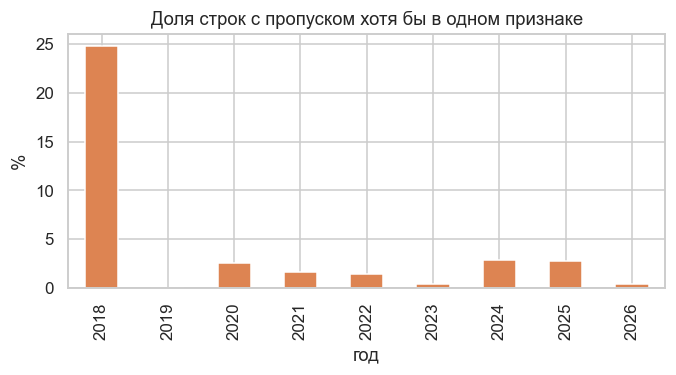

In [43]:
miss_by_year = ds.groupby(ds.trade_date.dt.year)[FEATURES].apply(lambda t: t.isna().any(axis=1).mean() * 100)
fig, ax = plt.subplots(figsize=(7, 3))
miss_by_year.plot.bar(ax=ax, color="#dd8452")
ax.set(title="Доля строк с пропуском хотя бы в одном признаке", xlabel="год", ylabel="%")
plt.show()

В таблице 0.80% пустых ячеек, хотя бы один пропуск есть в 3.72% строк, и все они в признаках.

**Причины:**
- **Недостаточная прошлая история** объясняет почти все пропуски признаков: например, `vol_63d` (3.72%) почти целиком из-за первых 62 дней каждой бумаги, `ret_21d` и `vol_21d` из-за первых 21.
- **Исключение:** по `ret_1d`, `ret_5d`, `ret_21d`, `vol_5d`, `vol_21d` лишних 83 строки. Это первые дни торгов новых бумаг без цены (CNRU 39, HEAD 29, YDEX 12, ENPG 2, RENI 1): предыдущей цены нет, взять нечего.
- **Конец будущего окна** относится к таргету, он разобран в разделе 12.2.

-->
- Пропуски в начале истории не нужно заполнять: это не ошибка данных. 
- Первые дни без цены у новых бумаг и 18 строк с нулевой волатильностью требуют решения (исключить или пометить).

## 10. Распределения признаков
Графики обрезаны по 1–99-му перцентилю, в заголовке указано, сколько значений осталось за пределами.

In [44]:
ds[FEATURES].describe(percentiles=[.01, .25, .5, .75, .99]).T

,count,mean,std,min,1%,25%,50%,75%,99%,max
ret_1d,"76,716.0000",0.0002,0.0223,-0.5319,-0.0557,-0.0095,-0.0002,0.0096,0.0585,0.5441
ret_5d,"76,540.0000",0.0010,0.0512,-0.7587,-0.1437,-0.0210,0.0014,0.0248,0.1273,0.8309
ret_21d,"75,836.0000",0.0039,0.1029,-0.9548,-0.3219,-0.0452,0.0072,0.0607,0.2471,0.6484
vol_5d,"76,540.0000",0.0173,0.0140,0.0000,0.0029,0.0095,0.0143,0.0212,0.0663,0.2575
vol_21d,"75,836.0000",0.0188,0.0121,0.0000,0.0054,0.0119,0.0161,0.0220,0.0696,0.1715
vol_63d,"73,988.0000",0.0196,0.0106,0.0038,0.0068,0.0132,0.0171,0.0228,0.0628,0.1064
range_vol_21d,"75,880.0000",0.0198,0.0119,0.0000,0.0068,0.0129,0.0171,0.0230,0.0693,0.1448
drawdown_21d,"75,880.0000",-0.0544,0.0613,-0.6156,-0.2910,-0.0751,-0.0368,-0.0120,0.0000,0.0000
turnover_21d,"75,963.0000","1,913,569,115.5525","3,361,909,099.4414",0.0000,"12,021,141.6375","368,396,513.2143","868,584,107.0190","1,916,653,478.7762","16,128,957,251.1613","70,954,977,106.0143"
turnover_ratio_5_63,"74,115.0000",1.0352,0.5921,0.0000,0.1941,0.6841,0.9178,1.2275,3.1776,9.6732


### 10.1 Доходности

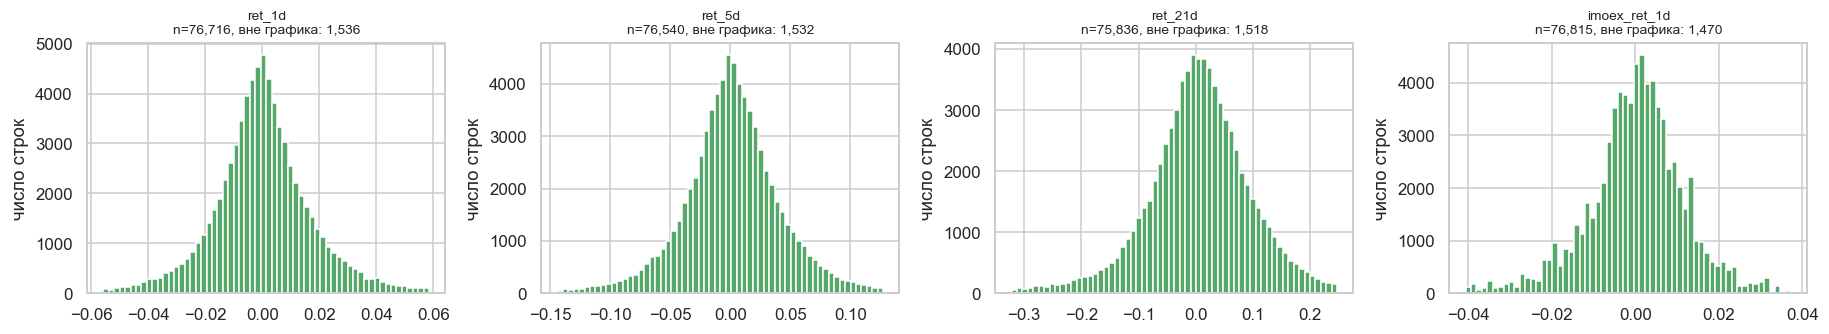

In [45]:
hist_panel(ds, ['ret_1d', 'ret_5d', 'ret_21d', 'imoex_ret_1d'], ncols=4, color='#55a868')

### 10.2 Волатильности

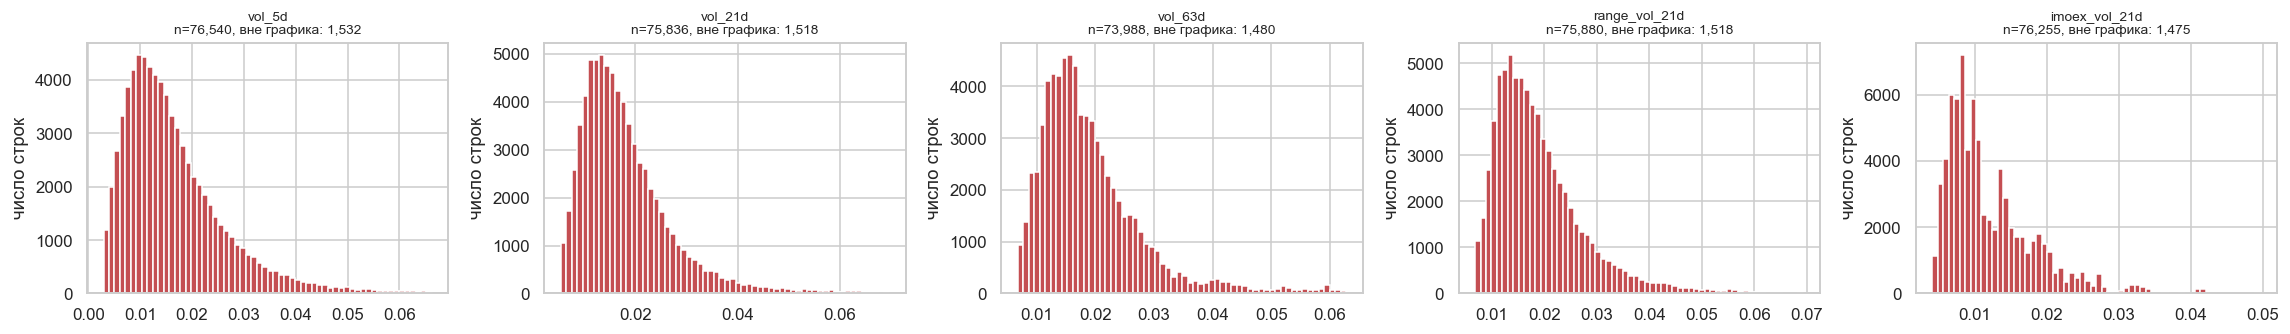

In [46]:
hist_panel(ds, ['vol_5d', 'vol_21d', 'vol_63d', 'range_vol_21d', 'imoex_vol_21d'], ncols=5, color='#c44e52')

### 10.3 Просадка и оборот

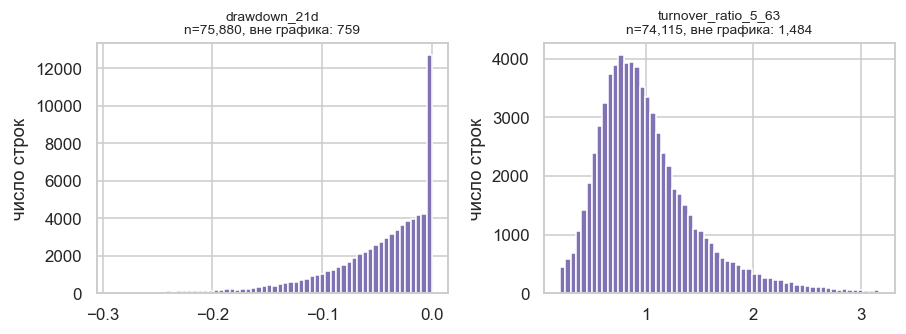

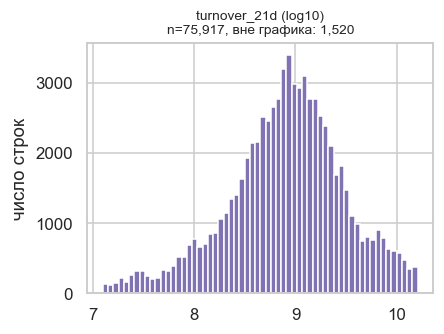

In [47]:
hist_panel(ds, ['drawdown_21d', 'turnover_ratio_5_63'], ncols=2, color='#8172b3')
hist_panel(ds, ['turnover_21d'], ncols=1, logx=True, color='#8172b3')

vol_21d == 0 (нулевая RMS): 18 строк


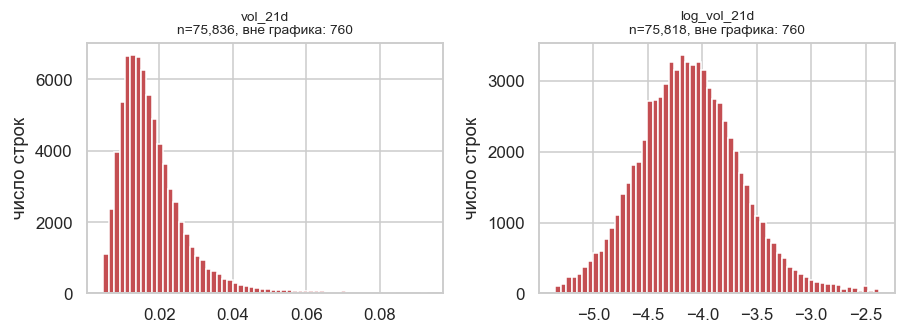

In [48]:
tmp = ds[["vol_21d"]].assign(log_vol_21d=np.log(ds["vol_21d"].where(ds["vol_21d"] > 0)))
print("vol_21d == 0 (нулевая RMS):", int((ds["vol_21d"] == 0).sum()), "строк")
hist_panel(tmp, ["vol_21d", "log_vol_21d"], ncols=2, clip=(0.005, 0.995), color="#c44e52")


- **Доходности:** дневная `ret_1d` симметрична около нуля (медиана −0.0002, стандартное отклонение 0.022), но хвосты тяжелые: 99-й перцентиль 5.8%, а максимум по модулю доходит до 54%.
- **Волатильности** (`vol_5d`, `vol_21d`, `vol_63d`, `range_vol_21d`) смещены вправо: медиана `vol_21d` 0.0161, среднее 0.0188, максимум 0.17. Оценка Паркинсона близка к RMS-волатильности по форме и по уровню (медиана 0.0171).
- **Просадка:** по определению ≤ 0, медиана −3.7%, у 1% строк просадка глубже −29%.
- **Оборот** (`turnover_21d`) очень скошен: среднее 1.9 млрд, медиана 0.87 млрд, максимум 71 млрд.
- **`turnover_ratio_5_63`:** медиана 0.92, среднее 1.04, максимум 9.7.



-->
- Для модели оборот нужно логарифмировать, а хвосты доходностей обрезать (винзоризация), иначе несколько дней 2022 года будут определять результат.
- Таргет по плану `ln(sqrt(mean(r²)))` при нулевой RMS не определен (−∞). Мы ставим в этих строках `NaN` (18 строк по окну прошлых дней, число для таргета в разделе 12.2).

## 11. Флаги и сводные таблицы с признаками
### 11.1 Флаги

In [49]:
flags = pd.DataFrame({f: ds[f].value_counts().reindex([0, 1], fill_value=0) for f in FLAGS}).T
flags.columns = ["0", "1"]
flags["доля единиц, %"] = flags["1"] / len(ds) * 100
flags

,0,1,"доля единиц, %"
zero_volume,76605,238,0.3097
halt_2022,76790,53,0.0690
big_move,76782,61,0.0794


In [50]:
big = ds[ds.big_move == 1]
print("big_move по годам:", big.groupby(big.trade_date.dt.year).size().to_dict())
big.assign(abs_ret=big.ret_1d.abs()).sort_values("abs_ret", ascending=False).drop(columns="abs_ret")[
    ["trade_date", "secid", "ret_1d"]].head(10)

big_move по годам: {2018: 2, 2020: 3, 2022: 49, 2025: 1, 2026: 6}


,trade_date,secid,ret_1d
72396,2022-03-29,VKCO,0.5441
74613,2022-02-24,VTBR,-0.5319
23282,2022-02-24,IRAO,-0.4714
55862,2022-02-24,SBER,-0.4559
49196,2022-02-24,ROSN,-0.4511
72391,2022-02-24,VKCO,-0.4400
58084,2022-02-24,SBERP,-0.4368
10966,2026-04-13,CBOM,0.4313
16052,2022-02-24,FLOT,-0.3994
68195,2022-02-24,TATNP,-0.3788


`zero_volume = 1` в 238 строках (0.31%), `big_move = 1` в 61 (0.08%), `halt_2022 = 1` в 53 (0.07%). Из 61 строки с `big_move` 49 приходятся на 2022 год (в основном 2022-02-24), по остальным годам от 1 до 6.



--> `big_move` и `halt_2022` слишком редки, чтобы быть самостоятельными признаками: это маркеры для разбора данных. `halt_2022` стоит на строках, доходность которых перешагивает остановку торгов 28.02–23.03.2022 (строк за сами даты остановки в датасете нет), разбор в разделе 12.5. Рост CBOM на +43% 2026-04-13 не похож на сплит (цена выросла в 1.54 раза, раздел 7.3), это рыночное событие, которое стоит проверить по новостям.

### 11.2 По бумагам

In [51]:
by_secid = ds.groupby("secid").agg(
    сектор=("sector", "first"),
    привилегированная=("is_pref", "first"),
    строк=("trade_date", "size"),
    первая_дата=("trade_date", "min"),
    дней_без_сделок=("zero_volume", "sum"),
    big_move=("big_move", "sum"),
    медиана_vol_21d=("vol_21d", "median"),
    медиана_оборота_21d=("turnover_21d", "median"),
).sort_values("строк", ascending=False)
by_secid["первая_дата"] = by_secid["первая_дата"].dt.date
by_secid

,сектор,привилегированная,строк,первая_дата,дней_без_сделок,big_move,медиана_vol_21d,медиана_оборота_21d
secid,,,,,,,,
AFKS,финансы,0,2222,2018-01-03,1,1,0.0187,"736,136,425.8976"
SBER,финансы,0,2222,2018-01-03,1,2,0.0145,"11,490,668,354.8310"
NVTK,нефть и газ,0,2222,2018-01-03,1,1,0.0177,"1,786,184,465.9238"
AFLT,транспорт,0,2222,2018-01-03,1,3,0.0174,"888,128,399.8714"
PLZL,металлы и добыча,0,2222,2018-01-03,4,3,0.0176,"1,948,216,247.3333"
ROSN,нефть и газ,0,2222,2018-01-03,1,1,0.0151,"2,067,816,427.9048"
RTKM,телекоммуникации,0,2222,2018-01-03,1,1,0.0137,"239,848,928.5357"
RUAL,металлы и добыча,0,2222,2018-01-03,5,1,0.0197,"542,461,016.4500"
SBERP,финансы,1,2222,2018-01-03,1,2,0.0130,"952,970,796.3905"


### 11.3 По секторам и типу акции

In [52]:
def group_table(keys):
    return ds.groupby(keys).agg(
        бумаг=("secid", "nunique"),
        строк=("trade_date", "size"),
        доля_дней_без_сделок_pct=("zero_volume", lambda s: s.mean() * 100),
        медиана_ret_1d=("ret_1d", "median"),
        медиана_vol_21d=("vol_21d", "median"),
        медиана_range_vol_21d=("range_vol_21d", "median"),
        медиана_drawdown_21d=("drawdown_21d", "median"),
        медиана_оборота_21d=("turnover_21d", "median"),
    )

group_table("sector").sort_values("медиана_vol_21d", ascending=False)

,бумаг,строк,доля_дней_без_сделок_pct,медиана_ret_1d,медиана_vol_21d,медиана_range_vol_21d,медиана_drawdown_21d,медиана_оборота_21d
sector,,,,,,,,
информационные технологии,6,5537,2.6910,-0.0005,0.0201,0.0215,-0.0479,"787,866,380.6000"
транспорт,2,3748,0.1067,-0.0009,0.0182,0.0197,-0.0425,"625,925,035.8238"
металлы и добыча,9,17989,0.1445,-0.0002,0.0178,0.0186,-0.0436,"968,958,803.7381"
потребительский сектор,3,2403,0.8739,-0.0002,0.0168,0.0206,-0.0390,"145,448,162.3143"
финансы,11,18280,0.1149,-0.0001,0.0154,0.0164,-0.0334,"781,768,263.8310"
нефть и газ,9,19998,0.0650,-0.0001,0.0151,0.0155,-0.0354,"1,490,902,730.8929"
электроэнергетика,1,2222,0.0450,0.0000,0.0146,0.0157,-0.0331,"497,176,888.3702"
химия и нефтехимия,1,2222,0.0450,0.0000,0.0129,0.0149,-0.0280,"389,832,489.5476"
телекоммуникации,2,4444,0.0450,0.0000,0.0123,0.0138,-0.0268,"453,264,086.0048"


In [53]:
pref = ds.assign(тип=ds["is_pref"].map({0: "обыкновенная", 1: "привилегированная"}))
pref.groupby("тип").agg(
    бумаг=("secid", "nunique"), строк=("trade_date", "size"),
    медиана_vol_21d=("vol_21d", "median"), медиана_оборота_21d=("turnover_21d", "median"))

,бумаг,строк,медиана_vol_21d,медиана_оборота_21d
тип,,,,
обыкновенная,40,67955,0.0165,"908,130,630.4524"
привилегированная,4,8888,0.0136,"702,607,129.5329"


In [54]:
# пары «обыкновенная и привилегированная» одного эмитента
pairs = {"SBER": "SBERP", "SNGS": "SNGSP", "TATN": "TATNP"}
rows = []
for a, b in pairs.items():
    ia, ib = ds[ds.secid == a], ds[ds.secid == b]
    rows.append({"обыкновенная": a, "привилегированная": b,
                 "vol_21d обыкн.": ia.vol_21d.median(), "vol_21d прив.": ib.vol_21d.median(),
                 "оборот 21д обыкн.": ia.turnover_21d.median(), "оборот 21д прив.": ib.turnover_21d.median()})
pd.DataFrame(rows)

,обыкновенная,привилегированная,vol_21d обыкн.,vol_21d прив.,оборот 21д обыкн.,оборот 21д прив.
0,SBER,SBERP,0.0145,0.0130,"11,490,668,354.8310","952,970,796.3905"
1,SNGS,SNGSP,0.0164,0.0126,"908,386,433.4167","1,095,651,816.1869"
2,TATN,TATNP,0.0160,0.0154,"1,448,597,046.1857","346,173,824.2643"


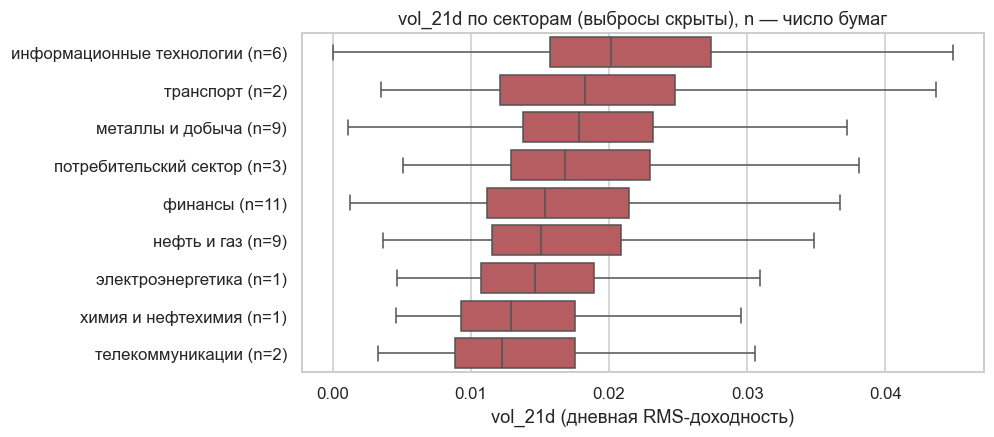

In [55]:
order = group_table("sector").sort_values("медиана_vol_21d", ascending=False).index
sizes = ds.groupby("sector")["secid"].nunique()
plot_df = ds.dropna(subset=["vol_21d"]).assign(сектор=lambda t: t["sector"].map(lambda s: f"{s} (n={sizes[s]})"))
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=plot_df, y="сектор", x="vol_21d", order=[f"{s} (n={sizes[s]})" for s in order],
            showfliers=False, color="#c44e52", ax=ax)
ax.set(title="vol_21d по секторам (выбросы скрыты), n — число бумаг", xlabel="vol_21d (дневная RMS-доходность)", ylabel="")
plt.show()

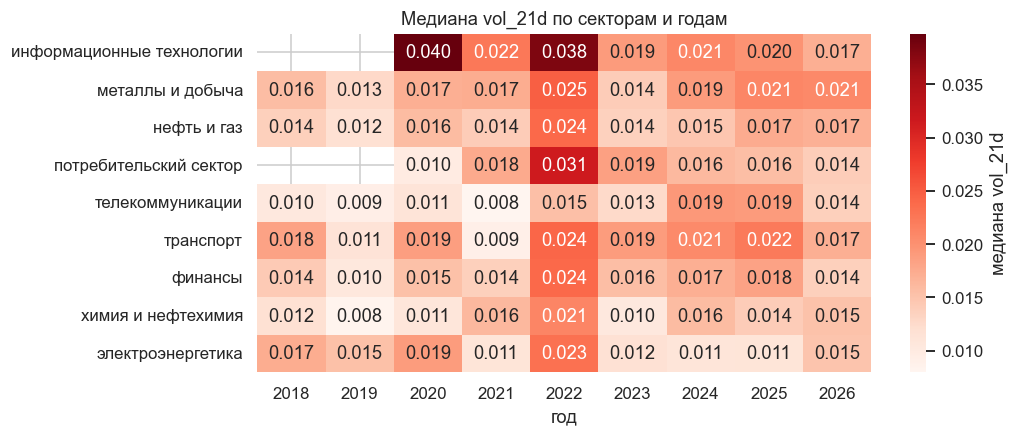

In [56]:
yr = ds.groupby([ds.trade_date.dt.year, "sector"])["vol_21d"].median().unstack()
fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(yr.T, annot=True, fmt=".3f", cmap="Reds", ax=ax, cbar_kws={"label": "медиана vol_21d"})
ax.set(title="Медиана vol_21d по секторам и годам", xlabel="год", ylabel="")
plt.show()


- **Сектора (медиана `vol_21d`):** самый волатильный IT (0.0201), затем транспорт (0.0182) и металлы (0.0178), самые спокойные телекоммуникации (0.0123) и химия (0.0129).
- **Тип акции:** у привилегированных медиана `vol_21d` ниже (0.0136 против 0.0165 у обыкновенных). В каждой из трех пар SBER/SBERP, SNGS/SNGSP, TATN/TATNP привилегированная менее волатильна. По обороту разница в разные стороны (SNGSP торгуется больше SNGS).
- **По годам:** во всех секторах самая высокая волатильность в 2022 году (медианы 0.016–0.038), у IT и потребительского сектора первые годы пусты, так как бумаг этих секторов еще не было.


**Что следует.**
- Сектор и тип акции несут информацию об уровне волатильности и могут быть полезными признаками, но разница между секторами небольшая (0.0123-0.0201), а в трех секторах 1–2 бумаги, так что различия могут отражать особенности отдельных эмитентов.
- Сильная зависимость от года (2022 в 1.5-2 раза выше соседних лет) означает, что случайный `train_test_split` недопустим: нужна временная разбивка.
- Результаты по привилегированным акциям основаны на 4 бумагах, соответственно это скорее гипотеза

---
# ЭТАП 3. Таргет
## 12. Расчет таргета `target_vol_21d` и `split`
К таблице `ds` добавляем два последних столбца из документа.

| Столбец | Как считается |
|---|---|
| **`target_vol_21d`** | `ln(sqrt(mean(ret_1d²)))` за дни `t+1…t+21` (то есть только будущее, внутри бумаги) |
| `split` | `train` / `val` / `test` / `gap` по датам |

**Правила (предварительные):**
1. **Нулевая RMS** (21 день без движения цены) дает `NaN`: логарифм нуля не определен.
2. **Неполные окна** (конец данных, дни без цены у новых бумаг) дают `NaN`.
3. **Границы выборок:** train до 2023-12-31, val 2024, test с 2025-01-01.
4. **`split = gap`:** день, у которого окно таргета `t+1…t+21` выходит в следующий период (или за конец данных). Так будущие окна обучающих меток не заходят в следующий период.

In [57]:
WIN = 21   # окно таргета, торговых дней
TRAIN_END, VAL_END = pd.Timestamp("2023-12-31"), pd.Timestamp("2024-12-31")
TARGET = "target_vol_21d"

# таргет: RMS доходностей за t+1…t+21, логарифм (sq и roll определены в разделе 7)
ms_fwd = roll(sq, WIN, "mean").groupby(by).shift(-WIN)
rms_fwd = np.sqrt(ms_fwd)
assert (ds[["trade_date", "secid"]].to_numpy() == d[["trade_date", "secid"]].to_numpy()).all()
ds[TARGET] = np.log(rms_fwd.where(rms_fwd > 0)).to_numpy()

# split по календарю: период даты t и период даты t+21 торгового дня
cal = pd.DataFrame({"trade_date": np.sort(ds["trade_date"].unique())})
cal["period"] = np.where(cal.trade_date <= TRAIN_END, "train", np.where(cal.trade_date <= VAL_END, "val", "test"))
cal["period_fwd"] = cal["period"].shift(-WIN)
cal["split"] = np.where(cal["period"] == cal["period_fwd"], cal["period"], "gap")
ds["split"] = ds["trade_date"].map(cal.set_index("trade_date")["split"])

MODEL_COLS = ["trade_date", "secid", "sector", "is_pref",
              "ret_1d", "ret_5d", "ret_21d", "vol_5d", "vol_21d", "vol_63d", "range_vol_21d",
              "drawdown_21d", "turnover_21d", "turnover_ratio_5_63", "imoex_ret_1d", "imoex_vol_21d",
              "zero_volume", "halt_2022", "big_move", "split", "target_vol_21d"]
ds = ds[MODEL_COLS]
assert not ds.duplicated(["trade_date", "secid"]).any()
print(f"ds (этап 3, форма model_dataset): {ds.shape[0]:,} строк, {ds.shape[1]} столбцов, последний столбец: {ds.columns[-1]}")

ds (этап 3, форма model_dataset): 76,843 строк, 21 столбцов, последний столбец: target_vol_21d


**Проверка вручную** (SBER, один день): таргет и `split`.

In [58]:
s = d[d.secid == "SBER"].reset_index(drop=True)
i = 500
r1 = np.log(s.close_f / s.close_f.shift(1))
tgt_manual = np.log(np.sqrt((r1[i+1:i+22] ** 2).mean()))
tgt_table = ds[ds.secid == "SBER"].reset_index(drop=True).loc[i, TARGET]
print(f"таргет SBER, строка {i}: вручную {tgt_manual:.6f}, в таблице {tgt_table:.6f}, совпало: {np.isclose(tgt_manual, tgt_table)}")
print("split в первый и в последний день бумаги SBER:", ds[ds.secid == "SBER"].split.iloc[[0, -1]].tolist())

таргет SBER, строка 500: вручную -4.321188, в таблице -4.321188, совпало: True
split в первый и в последний день бумаги SBER: ['train', 'gap']


Таргет и `split` добавлены к `ds`, получилась итоговая форма таблицы: 76 843 строки, 21 столбец в порядке из документа, `target_vol_21d` последний. Таргет считается только по будущему окну `t+1…t+21` внутри бумаги.

### 12.1 Паспорт итоговой таблицы

In [59]:
pd.Series({
    "строк": len(ds), "бумаг": ds.secid.nunique(), "столбцов": ds.shape[1], "последний столбец": ds.columns[-1],
    "ключ trade_date + secid уникален": not ds.duplicated(["trade_date", "secid"]).any(),
    "общая доля пустых ячеек, %": ds.isna().sum().sum() / ds.size * 100,
    "доля строк хотя бы с одним пропуском, %": ds.isna().any(axis=1).mean() * 100,
}).to_frame("значение")

,значение
строк,76843
бумаг,44
столбцов,21
последний столбец,target_vol_21d
ключ trade_date + secid уникален,True
"общая доля пустых ячеек, %",0.7918
"доля строк хотя бы с одним пропуском, %",4.9412


### 12.2 Пропуски таргета и их причины

In [60]:
ds["_nan_ret_in_window"] = (ds["ret_1d"].isna().astype(int).groupby(ds["secid"]).rolling(WIN, min_periods=WIN).sum()
                             .droplevel(0).groupby(ds["secid"]).shift(-WIN) > 0)
ds["_end_of_data"] = ds.groupby("secid").cumcount(ascending=False) < WIN
t_na = ds[TARGET].isna()

reasons = pd.Series({
    "конец будущего окна (последние 21 строка бумаги)": int((t_na & ds["_end_of_data"]).sum()),
    "в окне есть день без доходности (нет цены у новой бумаги)": int((t_na & ~ds["_end_of_data"] & ds["_nan_ret_in_window"]).sum()),
    "нулевая RMS (21 день без движения цены), логарифм не определен": int((t_na & ~ds["_end_of_data"] & ~ds["_nan_ret_in_window"]).sum()),
}).to_frame("строк")
reasons["доля, %"] = reasons["строк"] / len(ds) * 100
print("пропусков таргета:", int(t_na.sum()), f"({t_na.mean() * 100:.2f}% строк)")
print("значений -inf / +inf в таргете:", int(np.isinf(ds[TARGET]).sum()))
reasons

пропусков таргета: 1025 (1.33% строк)
значений -inf / +inf в таргете: 0


,строк,"доля, %"
конец будущего окна (последние 21 строка бумаги),924,1.2025
в окне есть день без доходности (нет цены у новой бумаги),83,0.1080
"нулевая RMS (21 день без движения цены), логарифм не определен",18,0.0234


### 12.3 Распределение таргета

                     count    mean    std     min      1%     25%     50%     75%     99%     max
target_vol_21d 75,818.0000 -4.1103 0.4959 -6.8183 -5.2201 -4.4320 -4.1275 -3.8162 -2.6643 -1.7632


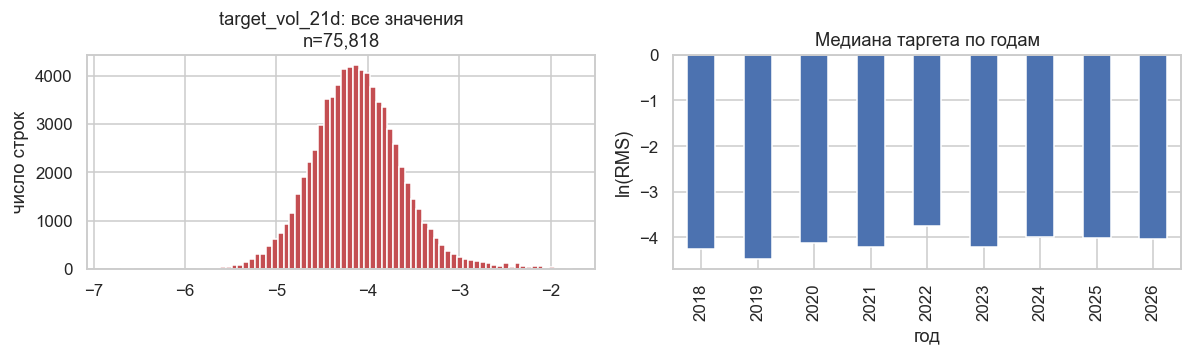

In [61]:
print(ds[TARGET].describe(percentiles=[.01, .25, .5, .75, .99]).to_frame(TARGET).T.to_string())
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].hist(ds[TARGET].dropna(), bins=80, color="#c44e52")
axes[0].set(title=f"{TARGET}: все значения\nn={ds[TARGET].notna().sum():,}", ylabel="число строк")
by_y = ds.dropna(subset=[TARGET]).groupby(ds.trade_date.dt.year)[TARGET].median()
by_y.plot.bar(ax=axes[1], color="#4c72b0")
axes[1].set(title="Медиана таргета по годам", xlabel="год", ylabel="ln(RMS)")
fig.tight_layout(); plt.show()

In [62]:
sec_t = ds.dropna(subset=[TARGET]).groupby("sector")[TARGET].agg(["count", "median", "std"]).sort_values("median", ascending=False)
sec_t.columns = ["строк", "медиана таргета", "std таргета"]
sec_t

,строк,медиана таргета,std таргета
sector,,,
информационные технологии,5313,-3.9041,0.4918
транспорт,3706,-4.0050,0.5233
металлы и добыча,17798,-4.0288,0.4269
потребительский сектор,2340,-4.0844,0.4803
финансы,18048,-4.1746,0.5143
нефть и газ,19809,-4.1943,0.4767
электроэнергетика,2201,-4.2248,0.4752
химия и нефтехимия,2201,-4.3502,0.4610
телекоммуникации,4402,-4.4021,0.5252


### 12.4 Разбиение `split`

In [63]:
sp = ds.groupby("split").agg(строк=("trade_date", "size"), первая_дата=("trade_date", "min"),
                              последняя_дата=("trade_date", "max"), бумаг=("secid", "nunique"),
                              с_таргетом=(TARGET, "count"))
sp["доля строк, %"] = sp["строк"] / len(ds) * 100
sp["первая_дата"] = sp["первая_дата"].dt.date
sp["последняя_дата"] = sp["последняя_дата"].dt.date
display(sp.reindex(["train", "val", "test", "gap"]))
print("строки с split == 'gap' имеют таргет:", int(ds.loc[ds.split == "gap", TARGET].notna().sum()), "из", int((ds.split == "gap").sum()))

,строк,первая_дата,последняя_дата,бумаг,с_таргетом,"доля строк, %"
split,,,,,,
train,46133,2018-01-03,2023-11-30,36,46127,60.0354
val,8881,2024-01-03,2024-12-02,40,8840,11.5573
test,19298,2025-01-03,2026-10-02,44,19244,25.1135
gap,2531,2023-12-01,2026-11-02,44,1607,3.2937


строки с split == 'gap' имеют таргет: 1607 из 2531



- **Итоговая таблица:** 76 843 строки, 21 столбец, пустых ячеек 0.79%, строк хотя бы с одним пропуском 4.94% (3.72% из-за признаков, еще 1.22% только из-за таргета).
- **Пропуски таргета:** 1 025 строк (1.33%): 924 строки конца будущего окна (последние 21 строка у каждой из 44 бумаг), 83 строки, в окне которых есть день без цены (новые бумаги), и 18 строк с нулевой RMS. Значений `±inf` нет.
- **Распределение:** n = 75 818, среднее −4.11, медиана −4.13, стандартное отклонение 0.50, 1-й и 99-й перцентили −5.22 и −2.66, диапазон от −6.82 до −1.76. Распределение близко к симметричному колоколу.
- **По секторам:** медиана таргета от −4.40 (телекоммуникации) до −3.90 (IT), разброс между секторами около 1 стандартного отклонения.
- **По годам:** медиана таргета от −4.46 (2019) до −3.74 (2022).
- **Разбиение:** train 46 133 строки (60.0%, 2018-01-03 — 2023-11-30, 36 бумаг), val 8 881 (11.6%, 2024-01-03 — 2024-12-02, 40 бумаг), test 19 298 (25.1%, 2025-01-03 — 2026-10-02, 44 бумаги), gap 2 531 (3.3%). Из gap 1 607 строк имеют таргет, но их окно заходит в следующий период, а 924 строки без таргета (конец данных).



-->
- Логарифм делает таргет близким к нормальному, но сильная зависимость от года (2022 и последние годы выше) означает, что оценка качества на разных периодах будет отличаться.
- Медиана таргета растет от train (−4.20) к val (−4.02) и test (−4.03): тестовый период в среднем волатильнее, поэтому baseline нужно сравнивать и по периодам.
- Состав бумаг в train, val и test разный (36, 40 и 44), часть бумаг в обучении отсутствует. Это нужно учитывать при оценке.
- Строки `gap` не должны попадать в обучение и оценку: их окно пересекает границу периодов.
- Нулевую RMS мы пока заменяем `NaN` (18 строк)

### 12.5 Остановка торгов 2022: доходность через паузу в окнах признаков и таргета
Торги акциями были остановлены с 28.02 по 23.03.2022, в датасете Kaggle строк за эти даты нет. Поэтому `ret_1d` в первый день торгов бумаги после паузы - это доходность почти за месяц, а не за день. Такая строка попадает:
- в окна признаков `vol_5d`, `vol_21d`, `vol_63d` следующих дней (5, 21 и 63 строки начиная с нее);
- в окно таргета предыдущих 21 строки (их будущее окно `t+1…t+21` включает этот день).

In [64]:
dh = ds.sort_values(["secid", "trade_date"]).reset_index(drop=True)
g = dh.groupby("secid")
span = ((dh["halt_2022"] == 1) & (dh["zero_volume"] == 0)).astype(int)   # день, чья доходность покрывает паузу

print(f"halt_2022 = 1: {int(dh['halt_2022'].sum())} строк у {dh.loc[dh.halt_2022 == 1, 'secid'].nunique()} бумаг; "
      f"из них дней с доходностью через паузу: {int(span.sum())}")
print(f"IMOEX за паузу (2022-02-25 → 2022-03-24): {dh.loc[dh.trade_date == '2022-03-24', 'imoex_ret_1d'].iloc[0]:+.3f}")
dh.loc[span == 1, "ret_1d"].describe(percentiles=[.1, .5, .9]).to_frame("ret_1d через паузу").T.round(3)

halt_2022 = 1: 53 строк у 35 бумаг; из них дней с доходностью через паузу: 35
IMOEX за паузу (2022-02-25 → 2022-03-24): +0.043


,count,mean,std,min,10%,50%,90%,max
ret_1d через паузу,35.0000,0.0570,0.1490,-0.2240,-0.1300,0.0510,0.1780,0.5440


In [65]:
contains = {}
for w in (5, 21, 63):
    contains[f"vol_{w}d"] = span.groupby(dh["secid"]).transform(lambda s: s.rolling(w, min_periods=1).sum()) > 0
contains["target_vol_21d"] = span.groupby(dh["secid"]).transform(lambda s: s[::-1].rolling(WIN, min_periods=1).sum()[::-1].shift(-1)) > 0

tab = pd.DataFrame({k: [int(v.sum()), round(v.mean() * 100, 2)] for k, v in contains.items()},
                   index=["строк, в окне которых есть день через паузу", "доля всех строк, %"]).T
tab["все в train"] = [bool((dh.loc[v, "split"] == "train").all()) for v in contains.values()]
tab

,"строк, в окне которых есть день через паузу","доля всех строк, %",все в train
vol_5d,175.0000,0.2300,True
vol_21d,735.0000,0.9600,True
vol_63d,"2,205.0000",2.8700,True
target_vol_21d,735.0000,0.9600,True


In [66]:
y22 = dh[dh["trade_date"].dt.year == 2022]
cmp = pd.DataFrame({
    "окно таргета содержит паузу": y22.loc[contains["target_vol_21d"].loc[y22.index], TARGET].describe(),
    "остальные строки 2022 года": y22.loc[~contains["target_vol_21d"].loc[y22.index], TARGET].describe(),
}).T[["count", "mean", "50%", "std"]].round(3)
cmp

,count,mean,50%,std
окно таргета содержит паузу,735.0000,-2.4850,-2.4470,0.3480
остальные строки 2022 года,"7,490.0000",-3.8170,-3.8000,0.5160



- `halt_2022 = 1` в 53 строках у 35 бумаг: 35 дней, чья доходность перешагивает паузу (у 28 бумаг это 2022-03-24, у 7 бумаг торги возобновились 28–30 марта), и 18 строк без сделок между 24.03 и днем возобновления.
- Доходность через паузу: медиана +5.1%, от −22% до +54% (VKCO 2022-03-29), при росте IMOEX за тот же период на 4.3%.
- Такой день попадает в окно `vol_21d` у 735 строк (0.96%), `vol_63d` у 2 205 (2.87%) и в окно таргета у 735 строк (0.96%). Все они в `train`.
- Таргет в строках, чье окно содержит паузу: медиана −2.45 против −3.80 у остальных строк 2022 года. В эти же окна обычно попадает и 24.02.2022, поэтому разница — это эффект кризиса целиком, а не только склеенной доходности.



-->
- Доходность через паузу — это доходность почти за месяц, записанная как дневная. В окне на 21 день она весит как один день, поэтому оценку волатильности искажает, но не на порядок.
- Варианты для команды: (а) оставить как есть, `halt_2022` служит маркером; (б) исключить из обучения строки, чье окно таргета содержит паузу (735 строк, 0.96%); (в) делить доходность через паузу на число пропущенных торговых дней. Пока выбран вариант (а)

## 13. Ограничения выборки

- **Фиксированный состав (текущий IMOEX).** Список бумаг — состав на 2026-11-02. Результаты относятся к этим 44 бумагам, а не к индексу в прошлом: выбывшие бумаги в выборку не входят (смещение выживших), а 12–14% наших строк в 2021–2024 годах приходятся на дни, когда бумаги еще не было в индексе. У 6 бумаг (YDEX, T, X5, VKCO, RAGR, HEAD) нет истории под старым тикером (раздел 5.1).
- **Разная длина истории.** У 28 бумаг ряд с 2018 года, у остальных он начинается позже (самая короткая история у DOMRF, с 2025-11-20). Окна на 21 и 63 дня для них стартуют позже, а для самых новых бумаг данных мало для обучения.
- **Предварительные признаки.** Дивиденды взяты с `dohod.ru` (парсинг HTML, может измениться или содержать ошибки), сплиты - по официальному списку MOEX (5 событий, пропущенных не найдено), границы `train/val/test` выбраны нами.
- **Остановка торгов 2022 года:** в датасете Kaggle строк за эти даты нет (разрыв календаря 2022-02-25 → 2022-03-24), доходность первого дня после остановки накрывает весь период. Такие строки помечены `halt_2022`, они попадают в окно таргета 735 строк (0.96%, все в `train`), раздел 12.5.
- **Индекс ценовой, акции с дивидендами.** `imoex_ret_1d` и `imoex_vol_21d` считаются по IMOEX, это индекс цены без дивидендов, а `ret_1d` акций учитывает дивиденды (полная доходность). Для таргета это неважно (он считается только по самой акции), для признаков рыночного фона эффект небольшой и сезонный (дни массовых экс-дат в мае–июле). Но если дальше считать бету, избыточную доходность или корреляции с индексом, сравнивать надо осторожно: у бумаг появится небольшой систематический «плюс» порядка дивидендной доходности --> скорее всего нужно будет брать Индекс полной доходности MCFTR
- **Неравномерность секторов.** Часть секторов (электроэнергетика, химия — по одной бумаге; транспорт, телеком — по две) представлена очень малым числом бумаг, сравнения по ним ненадежны

## 14. Идеи для следующего этапа

> **Это не вошло в `model_dataset.csv`.** Пункты ниже - кандидаты на этап feature engineering и доработку данных. В текущей таблице их нет, в EDA они не проверялись (если не сказано иное).

**Данные и состав выборки**
| Идея | Зачем | Источник |
|---|---|---|
| История переименованных бумаг до смены тикера | удлинить историю 6 бумаг из нашего списка (YDEX, T, X5 и др.), не меняя состав | MOEX ISS по старым тикерам (YNDX, TCSG, FIVE, MAIL, AGRO, HHRU) |
| Веса бумаг в индексе как признак или как вес наблюдения | крупные бумаги важнее для портфеля на IMOEX | `data/raw/imoex_composition.csv` (уже скачан, раздел 5.1) |

**Корпоративные события**
| Идея | Зачем | Источник |
|---|---|---|
| Дивидендные признаки: доходность ближайшей выплаты, дней до экс-даты, был ли дивиденд в окне таргета | экс-дата дает предсказуемый скачок цены, вокруг нее меняется поведение бумаги | `data/raw/dividends.csv` (уже есть, включая прогнозы) |
| Даты отчетности, собраний акционеров, допэмиссий, buyback | всплески волатильности вокруг событий | сайты эмитентов, e-disclosure |

**Рыночная среда**
| Идея | Зачем | Источник |
|---|---|---|
| Ключевая ставка ЦБ и даты заседаний | режим рынка, волатильность в дни решений | ЦБ РФ |
| Курсы USD/RUB, CNY/RUB | важны для экспортеров (нефть, металлы, химия) | MOEX ISS (валютный рынок), ЦБ РФ |
| Нефть Brent, золото, металлы | отраслевые драйверы | внешние источники |
| Индекс волатильности RVI | ожидаемая волатильность рынка | MOEX ISS |
| Отраслевые индексы MOEX, бета к IMOEX, корреляции бумаг | контекст сектора; нужно для Risk Parity | MOEX ISS, расчет по нашим данным |
| Геополитические и санкционные события (разметка дат) | объяснить режимы 2022 года и позже | ручная разметка |

**Календарь**
| Идея | Зачем | Источник |
|---|---|---|
| День недели, конец месяца, квартала, года, предпраздничные дни | календарные эффекты в волатильности | календарь торгов (уже есть) |
| Даты экспирации фьючерсов и опционов, ребалансировки индекса | всплески оборота и движения цены | MOEX |

**Ликвидность и микроструктура**
| Идея | Зачем | Источник |
|---|---|---|
| `numtrades`, средний размер сделки | ликвидность; столбец уже есть в `base`, в признаки не вошел | Kaggle / MOEX ISS |
| Спред bid/ask, глубина стакана | ликвидность и риск резких движений | MOEX ISS (платные данные) |
| Внутридневная реализованная волатильность (5-минутные цены), утренняя и вечерняя сессии | точнее, чем дневные доходности и оценка Паркинсона | MOEX ISS (свечи) |

**Фундаментальные показатели**
| Идея | Зачем | Источник |
|---|---|---|
| Капитализация, free float, долговая нагрузка, мультипликаторы | связь риска с размером и финансовым положением компании | MOEX ISS (капитализация), отчетность |

**Что проверить уже в EDA как гипотезу (без добавления в таблицу):** календарные эффекты (волатильность по дням недели и месяцам), поведение волатильности вокруг дивидендных экс-дат и экспираций. Достаточно графика или таблицы, чтобы решить, стоит ли делать признак.